# 0. Basic Setup and stuff! 


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cortex
import pandas as pd 
import joblib
import sys 
sys.path.append('../main_experiment')


#this doesn't really belong in utils_pycrotex... but whatever..
from utils_pycortex import score_paths_from_exp_info, load_arr_from_score, load_sub_measure_from_score, get_pycortex_vol, filter_noisy_voxels, cortex_flat

#just load pre-calculated one
all_results = pd.read_csv("./all_results.csv")
# all_results.keys()

singlemodal_string = "---validation_method__CV-loss_criteria__MAE"
multimodal_string = "---validation_method__CV-loss_criteria__MAE-multimodal_method__concat_dataset"

best_models_exp_info = {
    #semantic models
    "semantic linear all voxels": "LLAMA7B_12-default-default---default",
    "semantic linear PCA" : "LLAMA7B_12-default-PCA_512---default",
    "semantic reLinear PCA" : "LLAMA7B_12-reducedLinear_256"+"-PCA_512" +singlemodal_string,
    "semantic MLP PCA" :  "LLAMA7B_12-MLPTanh_256" +"-PCA_512" + singlemodal_string, #"LLAMA7B_12-MLP_256" +"-PCA_512" + singlemodal_string, #
    #audio models 
    "audio linear all voxels": "whisper-large_final_default_default-default-default---default",
    "audio linear PCA" : "whisper-large_final_default_default-default-PCA_512---default",
    "audio reLinear PCA" : "whisper-large_final_default_default-reducedLinear_256-PCA_512---validation_method__CV-loss_criteria__MAE",
    "audio MLP PCA" : "whisper-large_final_default_default-MLPTanh_256-PCA_512---validation_method__CV-loss_criteria__MAE",
    #semantic + audio models
    "multimodal linear all voxels": 'LLAMA7B_12__whisper-large_final_default_default-default-default---default',
    "multimodal linear PCA" : "LLAMA7B_12__whisper-large_final_default_default-default-PCA_512---default",
    "multimodal reLinear PCA" : "LLAMA7B_12__whisper-large_final_default_default-reducedLinear_256-PCA_512---validation_method__CV-loss_criteria__MAE-multimodal_method__concat_dataset",
    "multimodal MLP PCA" : "LLAMA7B_12__whisper-large_final_default_default-MLPTanh_256-PCA_512---validation_method__CV-loss_criteria__MAE-multimodal_method__concat_dataset",
    "multimodal SepMLP PCA" : "LLAMA7B_12__whisper-large_final_default_default-MultimodalMLPTanh_16384,5120_1_256-PCA_512---validation_method__CV-loss_criteria__MAE-multimodal_method__multimodal_MLP"
}

#load the best models from the all_results
best_models = all_results[all_results['exp_info'].isin(best_models_exp_info.values())]

"""previous, relu models (also ReLinear and linear + PCA  that corresponds to its best, not set to match MLP)
best_models_exp_info = {
    #semantic models
    "semantic linear all voxels": "LLAMA7B_12-default-default---default",
    "semantic linear PCA" : "LLAMA7B_12-default-PCA_512---default",
    "semantic reLinear PCA" : "LLAMA7B_12-reducedLinear_256"+"-PCA_256" +singlemodal_string,
    "semantic MLP PCA" : "LLAMA7B_12-MLP_256" +"-PCA_512" + singlemodal_string,
    #audio models 
    "audio linear all voxels": "whisper-large_final_default_default-default-default---default",
    "audio linear PCA" : "whisper-large_final_default_default-default-PCA_256---default",
    "audio reLinear PCA" : "whisper-large_final_default_default-reducedLinear_256-PCA_512---validation_method__CV-loss_criteria__MAE",
    "audio MLP PCA" : "whisper-large_final_default_default-MLP_256-PCA_512---validation_method__CV-loss_criteria__MAE",
    #semantic + audio models
    "multimodal linear all voxels": 'LLAMA7B_12__whisper-large_final_default_default-default-default---default',
    "multimodal linear PCA" : "LLAMA7B_12__whisper-large_final_default_default-default-PCA_128---default",
    "multimodal reLinear PCA" : "LLAMA7B_12__whisper-large_final_default_default-reducedLinear_512-PCA_512---validation_method__CV-loss_criteria__MAE-multimodal_method__concat_dataset",
    "multimodal MLP PCA" : "LLAMA7B_12__whisper-large_final_default_default-MLP_256-PCA_512---validation_method__CV-loss_criteria__MAE-multimodal_method__concat_dataset"
}
"""


'previous, relu models (also ReLinear and linear + PCA  that corresponds to its best, not set to match MLP)\nbest_models_exp_info = {\n    #semantic models\n    "semantic linear all voxels": "LLAMA7B_12-default-default---default",\n    "semantic linear PCA" : "LLAMA7B_12-default-PCA_512---default",\n    "semantic reLinear PCA" : "LLAMA7B_12-reducedLinear_256"+"-PCA_256" +singlemodal_string,\n    "semantic MLP PCA" : "LLAMA7B_12-MLP_256" +"-PCA_512" + singlemodal_string,\n    #audio models \n    "audio linear all voxels": "whisper-large_final_default_default-default-default---default",\n    "audio linear PCA" : "whisper-large_final_default_default-default-PCA_256---default",\n    "audio reLinear PCA" : "whisper-large_final_default_default-reducedLinear_256-PCA_512---validation_method__CV-loss_criteria__MAE",\n    "audio MLP PCA" : "whisper-large_final_default_default-MLP_256-PCA_512---validation_method__CV-loss_criteria__MAE",\n    #semantic + audio models\n    "multimodal linear all vo

In [2]:
#LOADING ROI masks and ccmax
sub_list = ["S1", "S2", "S3"]

full_cc_max_dict = {}
lr_split_roi_mask_dict = {}
lr_combine_roi_mask_dict = {} 
for sub in sub_list:
    # full_cc_max_dict[sub] = np.nan_to_num(np.load(f'./misc_data_for_anlaysis/full_cc_max_{sub}.npy'))
    full_cc_max_dict[sub] = np.load(f'./misc_data_for_anlaysis/full_cc_max_{sub}.npy')
    lr_split_roi_mask_dict[sub] = np.load(f'./misc_data_for_anlaysis/UTS0{sub[-1]}-LRsplit_True-ROI_masks.npz')
    lr_combine_roi_mask_dict[sub] = np.load(f'./misc_data_for_anlaysis/UTS0{sub[-1]}-LRsplit_False-ROI_masks.npz')

#find common ROIs
common_rois = set(lr_combine_roi_mask_dict[sub_list[0]].keys())
for sub in sub_list[1:]:
    common_rois &= set(lr_combine_roi_mask_dict[sub].keys())
common_rois = list(common_rois)
len(common_rois)
#remove hMT from common_rois (cuz nothing there)
common_rois.remove('hMT')

common_rois.sort()

(95556,)
Background RRGGBBAA: ffffff00
Area 0:0:2062.8:1024 exported to 1547 x 768 pixels (72 dpi)


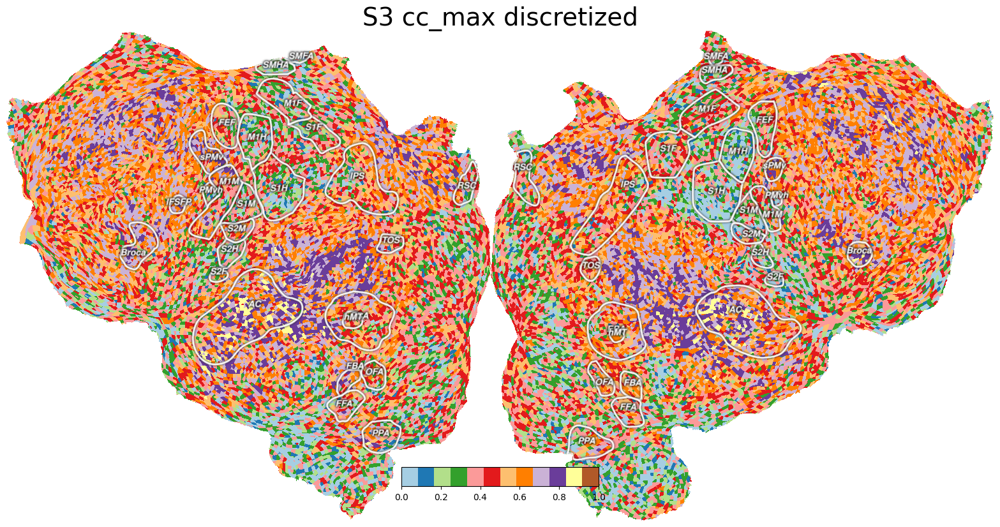

In [3]:
#trying to see cc-max wise values  
from utils_pycortex import score_paths_from_exp_info, load_arr_from_score, load_sub_measure_from_score, get_pycortex_vol, filter_noisy_voxels, cortex_flat
import utils_plotter
#=====SETTINGS======#
sub = "S3"

#example thing with NaN if cc_max < 0.35
to_plot = full_cc_max_dict[sub]
print(to_plot.shape) #example of loading

# Discretize the cc_max values into 10 bins from 0 to 1
bins = np.linspace(0, 1, 12)  # 10 bins from 0 to 1
discretized_values = np.digitize(to_plot, bins) - 1  # Subtract 1 to make bins 0-indexed

# Replace original values with bin indices
to_plot_discretized = bins[discretized_values]

# Some example
vol = get_pycortex_vol(to_plot_discretized, vmin=0, vmax=1, cmap = "Paired") #"Paired") #'BPROG')

cortex.quickshow(vol, with_colorbar=True, linewidth=4, thick=1,
                 with_curvature=True, with_rois=True, 
                 with_labels=True, height=768)
plt.title(f'{sub} cc_max discretized', fontsize=28)
plt.savefig(f'./FIGURES/CC_max_plots/{sub}_cc_max_discretized.png')
plt.show()



In [ ]:
import utils_resp
import utils_load_preds, utils_analyze_all, utils_analyze_tensession
all_resp_dict = utils_load_preds.get_test_resp_trimmed_allsub(subs = [sub])

In [ ]:
import config
import os 
REPO_DIR = "<DATA DIRECTORY>"  #! Replace with your actual data directory

config.R_SETTINGS['PCA_MODEL'] = os.path.join(REPO_DIR, "new_exp_files/PCA_weights") 

cc_max_to_plot = full_cc_max_dict[sub]
target_data_full = all_resp_dict[sub]['all_test_resp']
target_data_PCA = utils_resp.transform_data(target_data_full, sub, n_comp = 512)
target_data_recon = utils_resp.inverse_transform_data(target_data_PCA, sub, n_comp = 512)

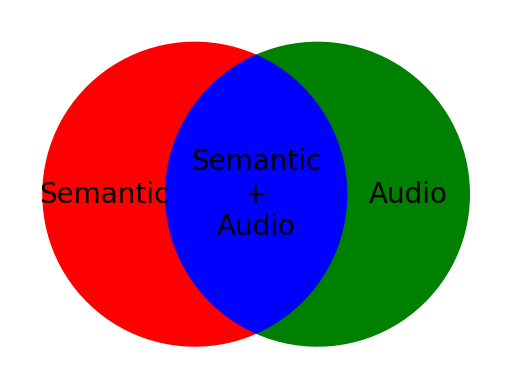

In [5]:
import matplotlib.pyplot as plt 
from matplotlib_venn import venn2

# Create a new figure
fig, ax = plt.subplots()

# Create a Venn diagram
venn = venn2(subsets=(1, 1, 1), set_labels=('',''))

# Set colors for the circles
venn.get_patch_by_id('10').set_color('red')
venn.get_patch_by_id('01').set_color('green')
venn.get_patch_by_id('11').set_color('blue')

# Set alpha for the circles
venn.get_patch_by_id('10').set_alpha(1.0)
venn.get_patch_by_id('01').set_alpha(1.0)
venn.get_patch_by_id('11').set_alpha(1.0)

# Remove the '1' labels
venn.get_label_by_id('10').set_text('Semantic')
venn.get_label_by_id('01').set_text('Audio')
venn.get_label_by_id('11').set_text('Semantic\n+\nAudio')

# Make the text bigger
for label in venn.set_labels:
    label.set_fontsize(20)
for label in venn.subset_labels:
    label.set_fontsize(20)

# Set the background color of the figure to transparent
fig.patch.set_facecolor('none')
ax.patch.set_facecolor('none')

# Display the Venn diagram
plt.savefig('./venn.svg', transparent=True)
plt.show()

# 0-0. timewise thing with subject-wise

In [ ]:
import joblib 
import numpy as np 
import os 
import sys 
sys.path.append('../decoding')
import config 
from utils_resp import get_test_resp
import matplotlib.pyplot as plt

import utils_load_preds, utils_analyze_all, utils_analyze_tensession

from utils_eval import spe_and_cc_norm, compute_r_single_trial, plot_corrs_all_trials, config_into_dict_for_saving

#let's compare 7B 12 and whisper large, default default! (at  first)

#=====SETTINGS======#
sub = "S1"
stories = config.test_list
llama_baseline_dir = "/<YOUR DIR>/LLAMA_Linear_Scores"
whisper_baseline_dir = "/<YOUR DIR>/Whisper_Linear_Scores"
multiMLP_baseline_dir = "/<YOUR DIR>/LLAMA7B_12__whisper-large_final_default_default-MLPTanh_256-PCA_512/validation_method__CV-loss_criteria__MAE-multimodal_method__concat_dataset/scores"


llama_MLP_dir = "/<YOUR DIR>/LLAMA7B_12-MLPTanh_256-PCA_512/validation_method__CV-loss_criteria__MAE/scores"
whisper_MLP_dir = "/<YOUR DIR>/whisper-large_final_default_default-MLPTanh_256-PCA_512/validation_method__CV-loss_criteria__MAE/scores"




# name_path_dict = {
#     "LLAMALinear": llama_baseline_dir,
#     "whisperLinear": whisper_baseline_dir,
#     "MultiMLP" : multiMLP_baseline_dir 
# }

name_path_dict = {
    "LLAMALinear": llama_MLP_dir, #multiMLP_baseline_dir,
    "whisperLinear": whisper_MLP_dir,  #whisper_baseline_dir,
    "MultiMLP" : multiMLP_baseline_dir 
}

# name_path_dict = {
#     "LLAMALinear": multiMLP_baseline_dir, #multiMLP_baseline_dir,
#     "whisperLinear": llama_MLP_dir,  #whisper_baseline_dir,
#     "MultiMLP" : multiMLP_baseline_dir 
# }


#define a function that calculates the modularity (Q) given a correlation matrix
import networkx as nx
import community
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scipy.stats as stats
import os



def get_modularity(corr_mat):
    #create a graph from the correlation matrix
    G = nx.Graph()
    G.add_nodes_from(range(corr_mat.shape[0]))
    for i in range(corr_mat.shape[0]):
        for j in range(i+1, corr_mat.shape[0]):
            G.add_edge(i, j, weight = corr_mat[i, j])

    #get the partition
    partition = community.best_partition(G, weight='weight')

    #get the modularity
    modularity = community.modularity(partition, G, weight='weight')
    return modularity
import networkx as nx
import numpy as np
from networkx.algorithms.community import greedy_modularity_communities

def get_modularity_deterministic(corr_mat):
    """
    Computes the modularity of a graph constructed from a correlation matrix
    using a deterministic greedy modularity maximization algorithm.
    
    Parameters:
    - corr_mat (numpy.ndarray): The correlation matrix (NxN).
    
    Returns:
    - float: The modularity score.
    """
    # Create a weighted graph from the correlation matrix
    G = nx.Graph()
    num_nodes = corr_mat.shape[0]
    G.add_nodes_from(range(num_nodes))
    
    # Add edges with weights
    for i in range(num_nodes):
        for j in range(i+1, num_nodes):
            weight = corr_mat[i, j]
            if weight > 0:  # Optionally, set a threshold to include edges
                G.add_edge(i, j, weight=weight)
    
    # Detect communities using the greedy modularity maximization algorithm
    communities = greedy_modularity_communities(G, weight='weight')
    
    # Convert communities to a partition dictionary
    partition = {}
    for community_id, community_nodes in enumerate(communities):
        for node in community_nodes:
            partition[node] = community_id
    
    # Compute modularity based on the detected partition
    modularity = compute_modularity(G, partition)
    
    return modularity

def compute_modularity(G, partition):
    """
    Computes the modularity of a graph based on a given partition.
    
    Parameters:
    - G (networkx.Graph): The graph.
    - partition (dict): A dictionary mapping node indices to community IDs.
    
    Returns:
    - float: The modularity score.
    """
    # Compute total weight (m)
    m = G.size(weight='weight')
    if m == 0:
        return 0.0  # Avoid division by zero
    
    # Initialize modularity
    Q = 0.0
    
    # Group nodes by community
    communities = {}
    for node, comm in partition.items():
        communities.setdefault(comm, set()).add(node)
    
    # Calculate modularity
    for comm, nodes in communities.items():
        # Sum of the weights of the edges within the community
        L_c = 0.0
        for i in nodes:
            for j in nodes:
                if G.has_edge(i, j):
                    L_c += G[i][j]['weight']
        
        # Sum of the degrees (strengths) of the nodes in the community
        K_c = sum([G.degree(n, weight='weight') for n in nodes])
        
        # Modularity contribution for this community
        Q += (L_c / (2 * m)) - (K_c / (2 * m)) ** 2
    
    return Q

/home/dyhan316/.conda/envs/brain_decoding/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
#test if the two functions are the same
test_matrix = np.random.rand(20, 20)

partition = community.best_partition(nx.Graph(test_matrix))
print(get_modularity(test_matrix))
print(get_modularity(test_matrix))
print(get_modularity(test_matrix))
print(get_modularity(test_matrix))

print(get_modularity_deterministic(test_matrix))
print(get_modularity_deterministic(test_matrix))
print(get_modularity_deterministic(test_matrix))
print(get_modularity_deterministic(test_matrix))



0.048075983965953535
0.05058096949938202
0.05296439567336045
0.05058096949938202
0.05296439567336045
0.05296439567336045
0.05296439567336045
0.05296439567336045


In [5]:
# Initialize a dictionary to store the relative error difference over time for each subject
relative_error_difference_dict = {}
all_test_resp_dict = {}


# Loop through each subject
for sub in sub_list:
    # Load the predictions and responses for the current subject
    all_pred_dict = utils_load_preds.get_model_pred_allsub(name_path_dict, subs=[sub])
    all_resp_dict = utils_load_preds.get_test_resp_trimmed_allsub(subs=[sub])
    
    # Extract the predictions and responses
    llama_vox_pred = all_pred_dict["LLAMALinear"][sub]['all_model_vox_pred']
    whisper_vox_pred = all_pred_dict["whisperLinear"][sub]['all_model_vox_pred']
    multi_vox_pred = all_pred_dict["MultiMLP"][sub]['all_model_vox_pred']
    all_test_resp = all_resp_dict[sub]['all_test_resp']
    
    # Compute the error statistics over time
    _, _, _, _, relative_error_difference_over_time_matrix, _ = utils_analyze_all.get_error_stats_over_time(all_test_resp, llama_vox_pred, whisper_vox_pred, normalize=False, error_type = 'mae')
    
    # Get the relative error difference over time for the current subject
    relative_error_difference_over_time = relative_error_difference_over_time_matrix[0, 1]
    
    # Store the relative error difference over time in the dictionary
    relative_error_difference_dict[sub] = relative_error_difference_over_time
    all_test_resp_dict[sub] = all_test_resp

# Plot the relative error difference over time for each subject for each ROI

# Initialize a dictionary to store the ROI-wise relative error difference over time for each subject
roi_timewise_error_dict = {}
roi_all_test_resp_dict = {}
# Loop through each subject

for sub in sub_list:
    # Initialize a dictionary to store the ROI-wise relative error difference over time for the current subject
    roi_timewise_error_dict[sub] = {}
    roi_all_test_resp_dict[sub] = {}
    
    # Loop through each ROI
    for i, roi in enumerate(common_rois):
        # Load the ROI mask for the current ROI
        roi_mask = lr_combine_roi_mask_dict[sub][roi]
        
        # Compute the mean relative error difference over time for the current ROI
        roi_timewise_error_dict[sub][roi] = np.mean(relative_error_difference_dict[sub][:, roi_mask], axis=1)
        roi_all_test_resp_dict[sub][roi] = all_test_resp_dict[sub][:, roi_mask]
        
        # Plot the mean relative error difference over time for the current ROI
        # plt.plot(roi_timewise_error_dict[sub][roi], label=roi)
    
    # # Add a legend to the plot
    # plt.legend()
    
    # # Add labels and title to the plot
    # plt.title(f"Subject {sub} Relative Error Difference Over Time")
    # plt.xlabel("Time")
    # plt.ylabel("Relative Error Difference")
    
    # # Display the plot
    # plt.show()



#get the average roi_all_test_resp_dict across time 
roi_all_test_resp_dict_avg = {}
for sub in sub_list:
    roi_all_test_resp_dict_avg[sub] = {}
    for roi in common_rois:
        roi_all_test_resp_dict_avg[sub][roi] = np.mean(roi_all_test_resp_dict[sub][roi], axis = 1)
        

100%|██████████| 1/1 [00:17<00:00, 17.94s/it]


In [8]:
#getting correlation matrix between subjects
def correlation_bw_roi_subjects(*arr):
    #arr : list of arrays of shape (n_timepoints)
    n_subjects = len(arr)
    n_timepoints = arr[0].shape[0]
    corr_mat = np.zeros((n_subjects, n_subjects))
    for i in range(n_subjects):
        for j in range(n_subjects):
            corr_mat[i, j] = np.corrcoef(arr[i], arr[j])[0, 1]
    return corr_mat, ((np.sum(corr_mat)-n_subjects)/2)/(n_subjects*(n_subjects-1)/2)
    
#testing 
arr1= np.random.rand(100)
arr2 = arr1 + np.random.rand(100)
arr3 = arr1 + 1

correlation_bw_roi_subjects(arr1, arr2, arr3)



(array([[1.        , 0.68331416, 1.        ],
        [0.68331416, 1.        , 0.68331416],
        [1.        , 0.68331416, 1.        ]]),
 0.7888761087558062)

In [9]:
# plot the average relative error difference over time for each ROI (subject-wise averaeg). also plot stdev
# Initialize a dictionary to store the average relative error difference over time for each ROI
avg_roi_timewise_error_dict = {}
std_roi_timewise_error_dict = {}


# rois_to_plot = ['AC','IFSFP','sPMv','Broca','M1H','S1H','M1M','S1M', 'RSC','PPA','EBA','FEF']
rois_to_plot = ['AC','IFSFP','sPMv','Broca','M1M','S1M','SMHA', 'FEF']
# Loop through each ROI
for i, roi in enumerate(rois_to_plot):
    # Initialize lists to store the relative error difference over time for each subject
    roi_timewise_error_list = []
    
    # Loop through each subject
    for sub in sub_list:
        # Append the relative error difference over time for the current subject and ROI to the list
        roi_timewise_error_list.append(roi_timewise_error_dict[sub][roi])
    
    # Compute the average relative error difference over time for the current ROI
    avg_roi_timewise_error = np.mean(roi_timewise_error_list, axis=0)
    std_roi_timewise_error = np.std(roi_timewise_error_list, axis=0)
    print(roi,avg_roi_timewise_error.mean(), avg_roi_timewise_error.std())
    
    # Store the average relative error difference over time for the current ROI in the dictionary
    avg_roi_timewise_error_dict[roi] = avg_roi_timewise_error
    std_roi_timewise_error_dict[roi] = std_roi_timewise_error

AC -0.011071448932013624 0.02560316210371119
IFSFP 0.007730308088225759 0.029318646625477115
sPMv 0.0014283247011597589 0.030556697233924054
Broca 0.005029332384283459 0.032371960287210136
M1M -0.004287313150409615 0.018988655519361873
S1M -0.0015940273278432972 0.0149170139669617
SMHA -0.000462937023786847 0.010518088793186147
FEF 0.0017177390133059549 0.011357918385760337


AC, error correlation : 0.2515506220587083, response correlation : 0.37581929247292845
Broca, error correlation : 0.14517342521276064, response correlation : 0.35169228513033346
EBA, error correlation : 0.06304302675700472, response correlation : 0.1756776557442746
FEF, error correlation : 0.07821229618044738, response correlation : 0.23964639377658634
FFA, error correlation : 0.0002051586975563661, response correlation : 0.1913629081185745
IFSFP, error correlation : 0.08762424693876018, response correlation : 0.2098693968634704
M1F, error correlation : 0.03199439555206814, response correlation : 0.14567330873507597
M1H, error correlation : 0.030697900217479496, response correlation : 0.08710730541032434
M1M, error correlation : 0.09544512788429153, response correlation : 0.11411833389659669
OFA, error correlation : -0.002663096435515063, response correlation : 0.16248152149363593
PMvh, error correlation : 0.035624173458112786, response correlation : -0.029282957093332396
PPA, error co

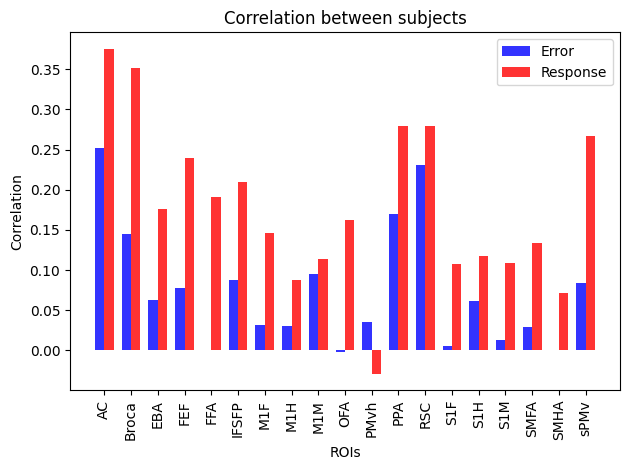

' \nIFSFP, error correlation : 0.14595886593866747, response correlation : 0.2098693968634704\nOFA, error correlation : 0.019166272544162737, response correlation : 0.16248152149363593\nPPA, error correlation : 0.12099053958845407, response correlation : 0.27970960072651874\nEBA, error correlation : 0.09490269021263464, response correlation : 0.1756776557442746\nSMFA, error correlation : 0.06204545084783645, response correlation : 0.1334979692378052\nRSC, error correlation : 0.20136776465375883, response correlation : 0.27935580988914444\nS1H, error correlation : 0.05822874268845979, response correlation : 0.11740049323700334\nS1M, error correlation : 0.015921031896997413, response correlation : 0.1083622762339278\nM1H, error correlation : 0.030329004325841735, response correlation : 0.08710730541032434\nsPMv, error correlation : 0.11124553590991508, response correlation : 0.26698318777743424\nM1M, error correlation : 0.11567154610691317, response correlation : 0.11411833389659669\nS1F

In [ ]:
avg_corr_dict = {}

for i,roi in enumerate(common_rois):
    #for error timeseires
    err_correlation_matrix, err_avg_corr = correlation_bw_roi_subjects(*[roi_timewise_error_dict[sub][roi] for sub in sub_list])
    #for response timeseries
    resp_correlation_matrix, resp_avg_corr = correlation_bw_roi_subjects(*[roi_all_test_resp_dict_avg[sub][roi] for sub in sub_list])
    
    print(f"{roi}, error correlation : {err_avg_corr}, response correlation : {resp_avg_corr}")
    avg_corr_dict[roi] = (err_avg_corr, resp_avg_corr)

#plotting (plot the bargraph comparing the two)
roi_list = list(avg_corr_dict.keys())
err_corrs = [avg_corr_dict[roi][0] for roi in roi_list]
resp_corrs = [avg_corr_dict[roi][1] for roi in roi_list]

fig, ax = plt.subplots()
x = np.arange(len(roi_list))
bar_width = 0.35
opacity = 0.8

rects1 = plt.bar(x, err_corrs, bar_width,
alpha=opacity,
color='b',
label='Error')

rects2 = plt.bar(x + bar_width, resp_corrs, bar_width,
alpha=opacity,
color='r',
label='Response')

plt.xlabel('ROIs')
plt.ylabel('Correlation')
plt.title('Correlation between subjects')
plt.xticks(x + bar_width/2, roi_list, rotation = 90)
plt.legend()

plt.tight_layout()
plt.show()

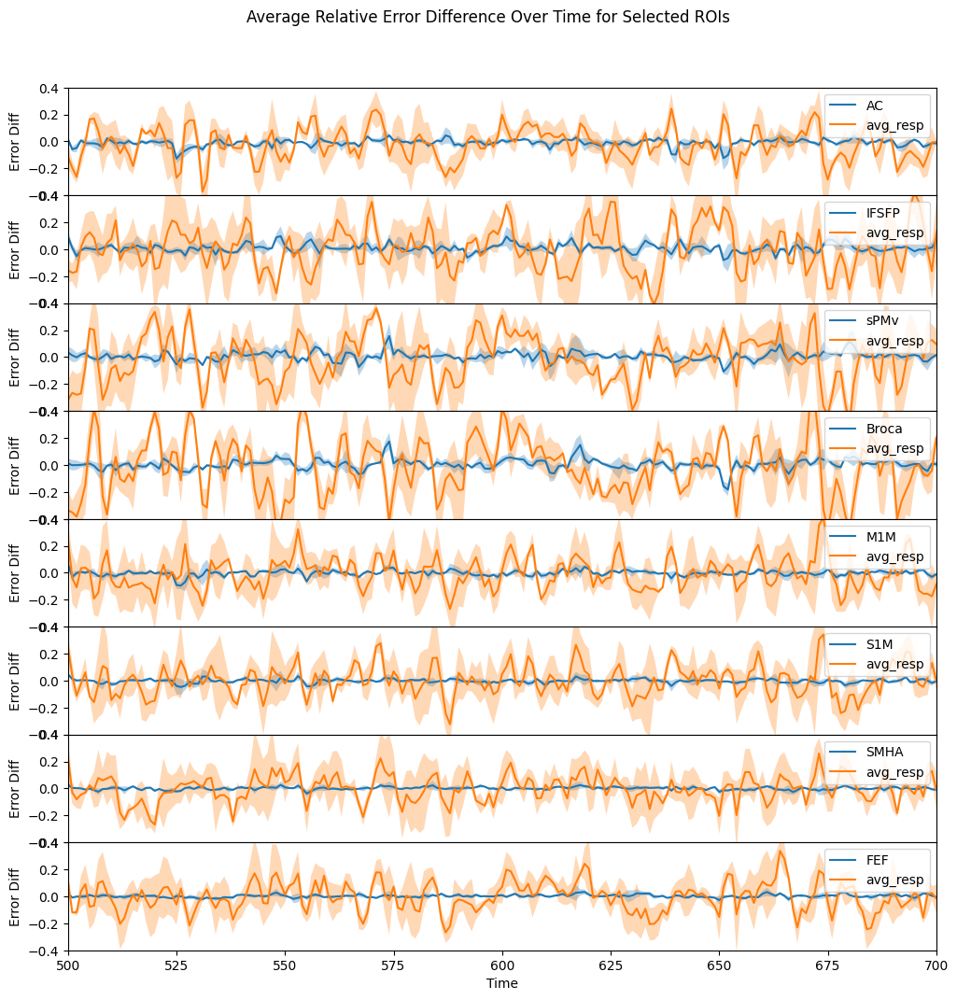

AC_S1 -0.011849649364029016 0.03367482195779789
AC_S2 -0.0035048971612541995 0.033160573857055856
AC_S3 -0.017859800270757658 0.04112313000570535
IFSFP_S1 0.003775503584487531 0.03177649709730581
IFSFP_S2 0.008416268890918203 0.039937146285853736
IFSFP_S3 0.010999151789271546 0.0641308147639685
sPMv_S1 0.0013054640068692507 0.04409635846372117
sPMv_S2 0.002609440616408744 0.04670731631557153
sPMv_S3 0.0003700694802012813 0.05518955929391417
Broca_S1 0.004813896791991708 0.04470246998598147
Broca_S2 0.006030727604814095 0.05747794571379609
Broca_S3 0.004243372756044574 0.045873019876914896
M1M_S1 -0.005106051763871549 0.03134480968558803
M1M_S2 -0.00236852801936672 0.031175420435903368
M1M_S3 -0.00538735966799058 0.027890623403151113
S1M_S1 -0.0027553179575592565 0.028012876015084832
S1M_S2 -0.0006211560630390432 0.02336980689507339
S1M_S3 -0.0014056079629315924 0.02491195709451879
SMHA_S1 -0.0005550735851326114 0.015405922834546608
SMHA_S2 0.00035728538929514917 0.0191780097658784
SMHA

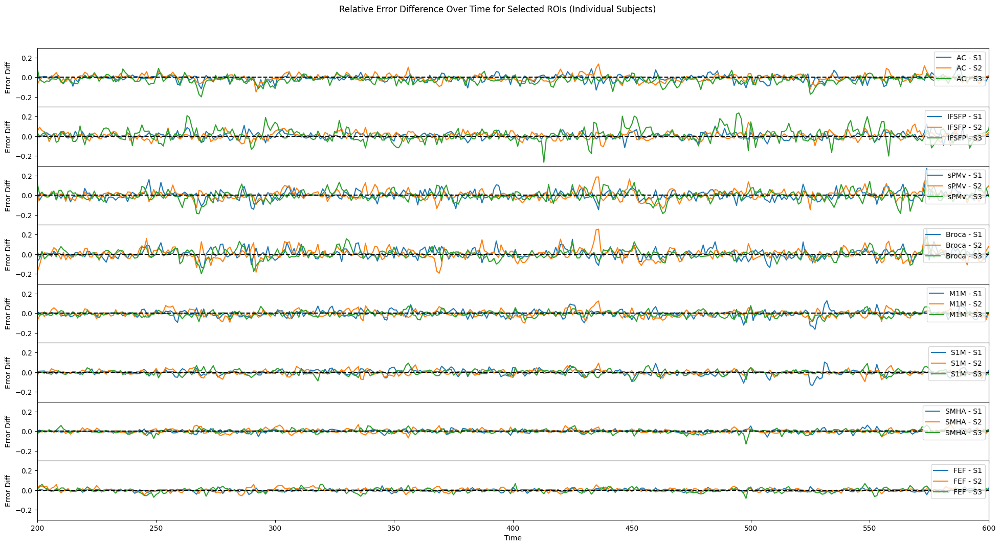

In [11]:

# Set up a shared x-axis, and plot each ROI in a separate but compact plot
fig, axs = plt.subplots(len(rois_to_plot), 1, figsize=(12, 12), sharex=True, gridspec_kw={'hspace': 0})

x = np.arange(avg_roi_timewise_error_dict[rois_to_plot[0]].shape[0])

for i, roi in enumerate(rois_to_plot):
    axs[i].plot(x, avg_roi_timewise_error_dict[roi], label=roi)
    axs[i].fill_between(x, avg_roi_timewise_error_dict[roi] - std_roi_timewise_error_dict[roi], 
                        avg_roi_timewise_error_dict[roi] + std_roi_timewise_error_dict[roi], alpha=0.3)
    
    
    #plot the average response over subject, mean and std using fill_between
    avg_resp = np.mean([roi_all_test_resp_dict_avg[sub][roi] for sub in sub_list], axis = 0)
    std_resp = np.std([roi_all_test_resp_dict_avg[sub][roi] for sub in sub_list], axis = 0)
    axs[i].plot(x, avg_resp, label = "avg_resp")
    axs[i].fill_between(x, avg_resp - std_resp, avg_resp + std_resp, alpha=0.3)
    ##########
    
    axs[i].set_ylabel("Error Diff")
    axs[i].legend(loc="upper right")

# Set common labels and limits
axs[-1].set_xlabel("Time")
fig.suptitle("Average Relative Error Difference Over Time for Selected ROIs", y=0.95)
axs[0].set_xlim([500, 700])
ylim = 0.4
for ax in axs:
    ax.set_ylim([-ylim, ylim])

plt.show()



# Set up a shared x-axis, and plot each ROI in a separate but compact plot
fig, axs = plt.subplots(len(rois_to_plot), 1, figsize=(24, 12), sharex=True, gridspec_kw={'hspace': 0})

x = np.arange(avg_roi_timewise_error_dict[rois_to_plot[0]].shape[0])

for i, roi in enumerate(rois_to_plot):
    for sub in sub_list:
        axs[i].plot(x, roi_timewise_error_dict[sub][roi], label=f"{roi} - {sub}")
        print(f'{roi}_{sub}',roi_timewise_error_dict[sub][roi].mean(), roi_timewise_error_dict[sub][roi].std())
        
        
        #plot subwise average response
        # axs[i].plot(x, roi_all_test_resp_dict_avg[sub][roi], label=f"resp {roi} - {sub}", linestyle='--')
    # Plot the average response over subject, mean and std using fill_between
    # avg_resp = np.mean([roi_all_test_resp_dict_avg[sub][roi] for sub in sub_list], axis=0)
    # std_resp = np.std([roi_all_test_resp_dict_avg[sub][roi] for sub in sub_list], axis=0)
    # axs[i].plot(x, avg_resp, label="avg_resp", linestyle='--')
    # axs[i].fill_between(x, avg_resp - std_resp, avg_resp + std_resp, alpha=0.3)
    
    axs[i].axhline(0, color='black', linestyle='--')
    axs[i].set_ylabel("Error Diff")
    axs[i].legend(loc="upper right")

# Set common labels and limits
axs[-1].set_xlabel("Time")
fig.suptitle("Relative Error Difference Over Time for Selected ROIs (Individual Subjects)", y=0.95)
axs[0].set_xlim([200, 600])
ylim = .3
for ax in axs:
    ax.set_ylim([-ylim, ylim])

plt.show()
    

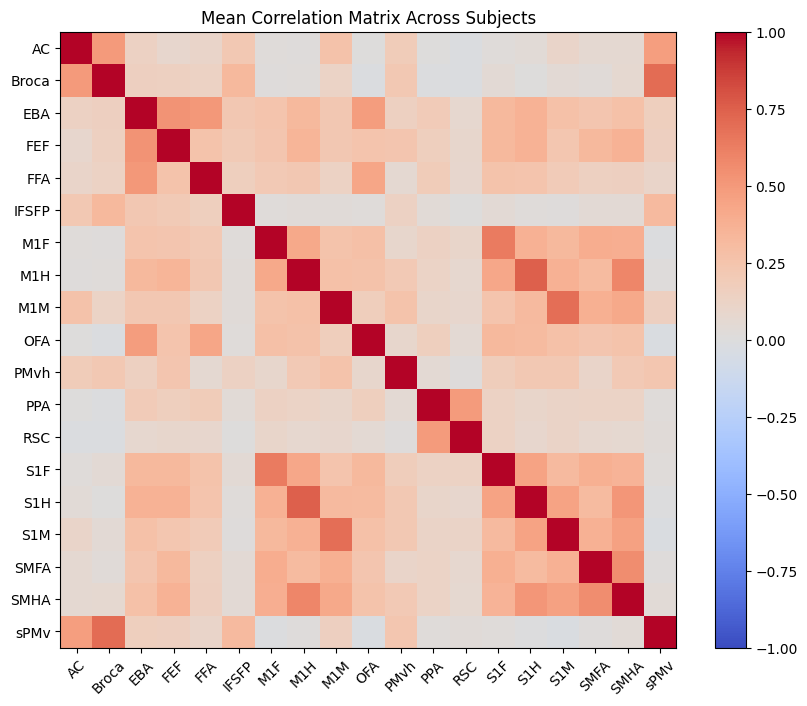

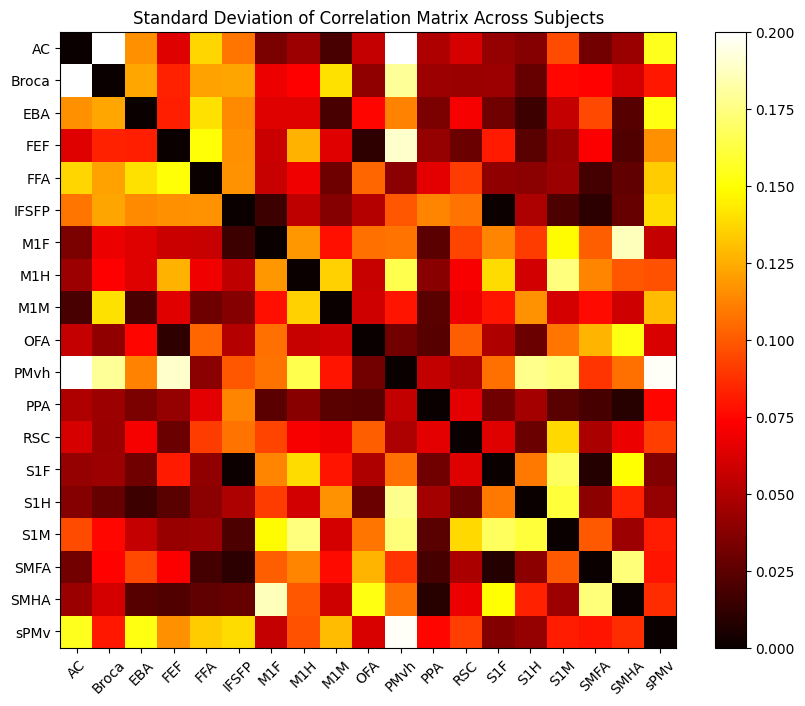

In [12]:
import numpy as np

import matplotlib.pyplot as plt

# Initialize a 3D numpy array to store the ROI-wise correlation matrix for each subject
roi_corr_matrix = np.full((len(sub_list), len(common_rois), len(common_rois)), np.nan)

# Loop through each subject
for sub_idx, sub in enumerate(sub_list):
    # Loop through each ROI
    for i, roi1 in enumerate(common_rois):
        # Loop through each ROI
        for j, roi2 in enumerate(common_rois):
            # Compute the correlation matrix for the current ROI pair
            corr_matrix = np.corrcoef(roi_timewise_error_dict[sub][roi1], roi_timewise_error_dict[sub][roi2])
            
            # Store the correlation value in the numpy array
            roi_corr_matrix[sub_idx, i, j] = corr_matrix[0, 1]

# Compute the mean and standard deviation correlation matrix across subjects
mean_corr_matrix = np.nanmean(roi_corr_matrix, axis=0)
std_corr_matrix = np.nanstd(roi_corr_matrix, axis=0)

# Plot the mean correlation matrix across subjects
plt.figure(figsize=(10, 8))
plt.imshow(mean_corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.title("Mean Correlation Matrix Across Subjects")
plt.xticks(ticks=np.arange(len(common_rois)), labels=common_rois, rotation=45)
plt.yticks(ticks=np.arange(len(common_rois)), labels=common_rois)
plt.show()

# Plot the standard deviation of the correlation matrix across subjects
plt.figure(figsize=(10, 8))
plt.imshow(std_corr_matrix, cmap='hot', vmin=0, vmax=0.2)
plt.colorbar()
plt.title("Standard Deviation of Correlation Matrix Across Subjects")
plt.xticks(ticks=np.arange(len(common_rois)), labels=common_rois, rotation=45)
plt.yticks(ticks=np.arange(len(common_rois)), labels=common_rois)
plt.show()

#also plot the roi x roi correlation matrix for each subject

# Initialize a dictionary to store the ROI-wise correlation matrix for each subject
roi_corr_matrix_dict = {}

# Loop through each subject

for sub_idx, sub in enumerate(sub_list):
    # Initialize a 2D numpy array to store the ROI-wise correlation matrix for the current subject
    roi_corr_matrix = np.full((len(common_rois), len(common_rois)), np.nan)
    
    # Loop through each ROI
    for i, roi1 in enumerate(common_rois):
        # Loop through each ROI
        for j, roi2 in enumerate(common_rois):
            # Compute the correlation matrix for the current ROI pair
            corr_matrix = np.corrcoef(roi_timewise_error_dict[sub][roi1], roi_timewise_error_dict[sub][roi2])
            
            # Store the correlation value in the numpy array
            roi_corr_matrix[i, j] = corr_matrix[0, 1]
    
    # Store the ROI-wise correlation matrix for the current subject in the dictionary
    roi_corr_matrix_dict
    
    # # Plot the ROI-wise correlation matrix for the current subject
    # plt.figure(figsize=(10, 8))
    # plt.imshow(roi_corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
    # plt.colorbar()
    # plt.title(f"Subject {sub} ROI-wise Correlation Matrix")
    # plt.xticks(ticks=np.arange(len(common_rois)), labels=common_rois, rotation=45)
    # plt.yticks(ticks=np.arange(len(common_rois)), labels=common_rois)
    # plt.show()
    
    # Store the ROI-wise correlation matrix for the current subject in the dictionary
    roi_corr_matrix_dict[sub] = roi_corr_matrix
    

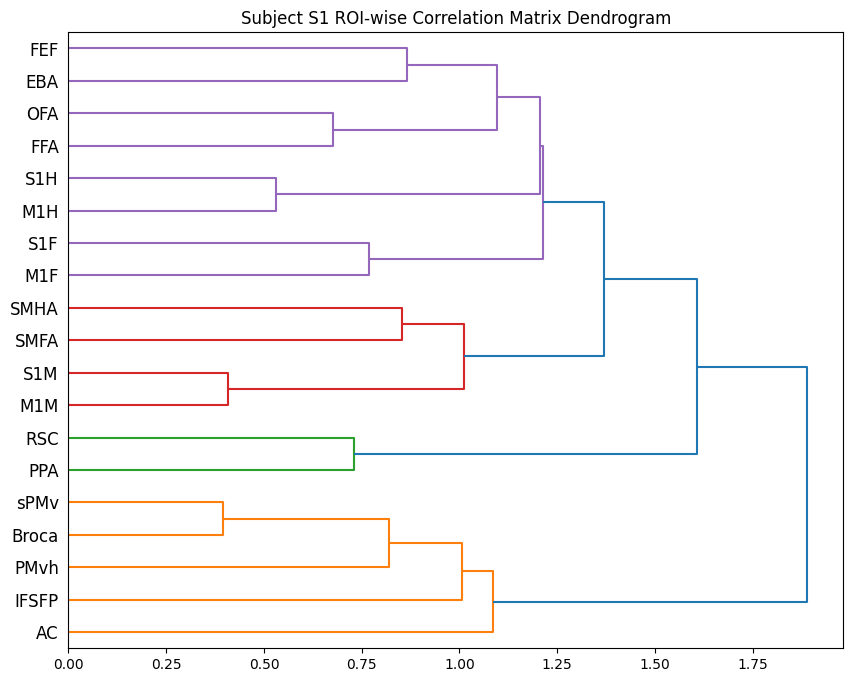

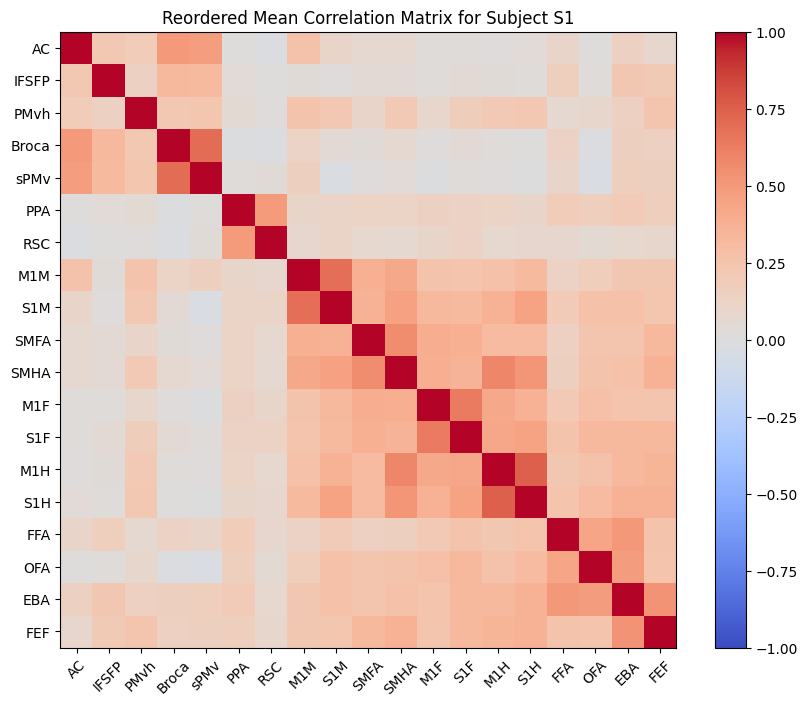

0.24816808402971713


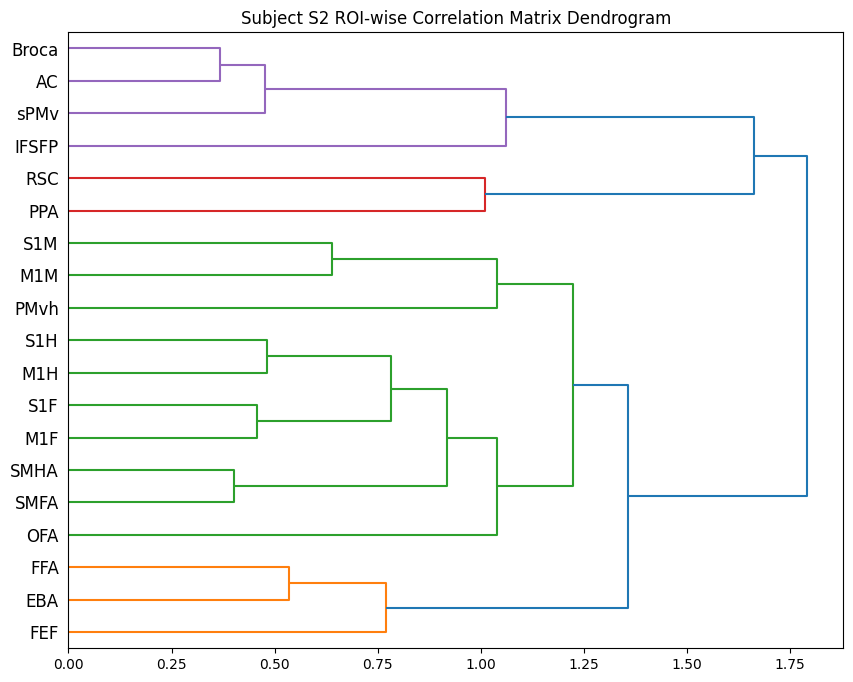

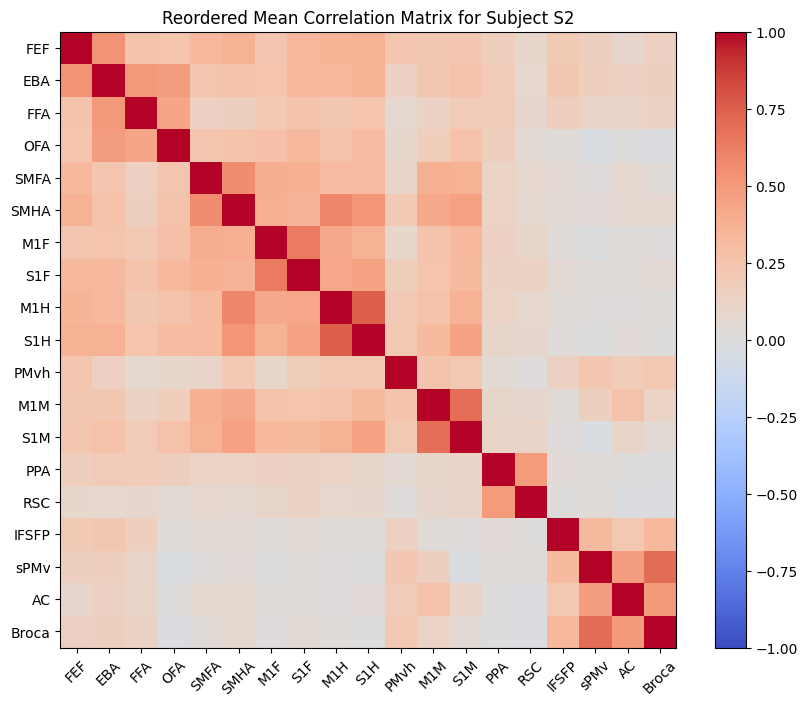

0.16020127930654696


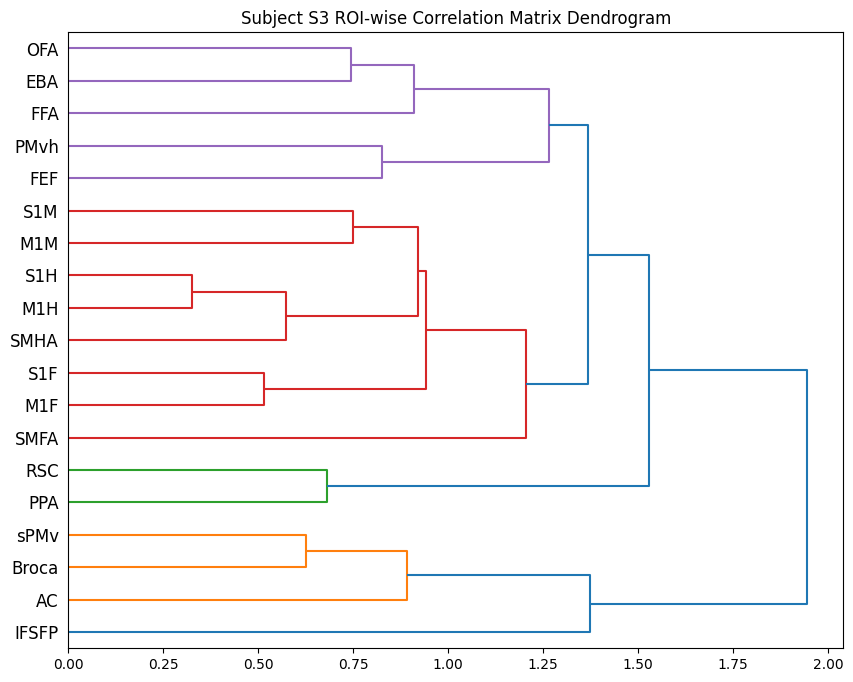

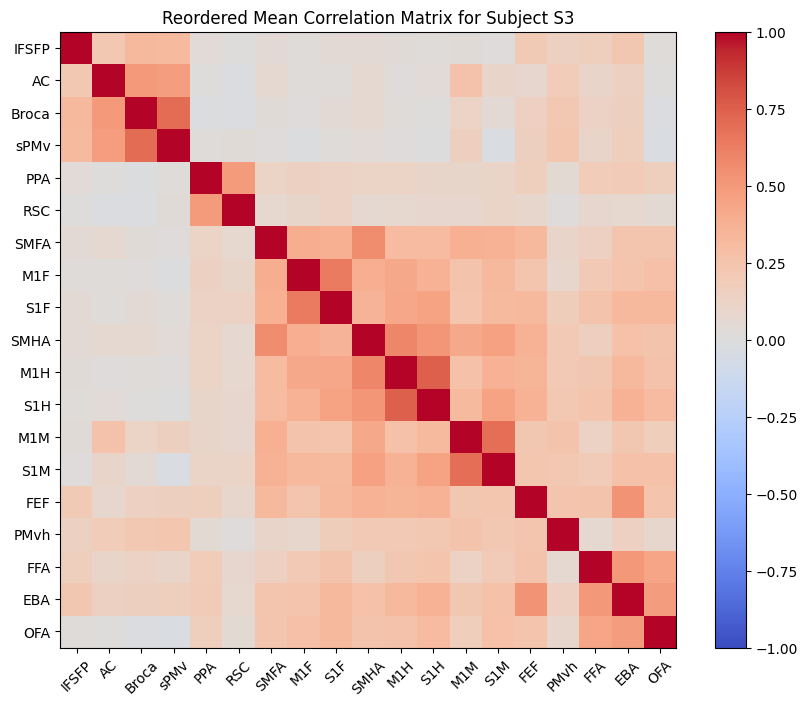

0.14695616568007058


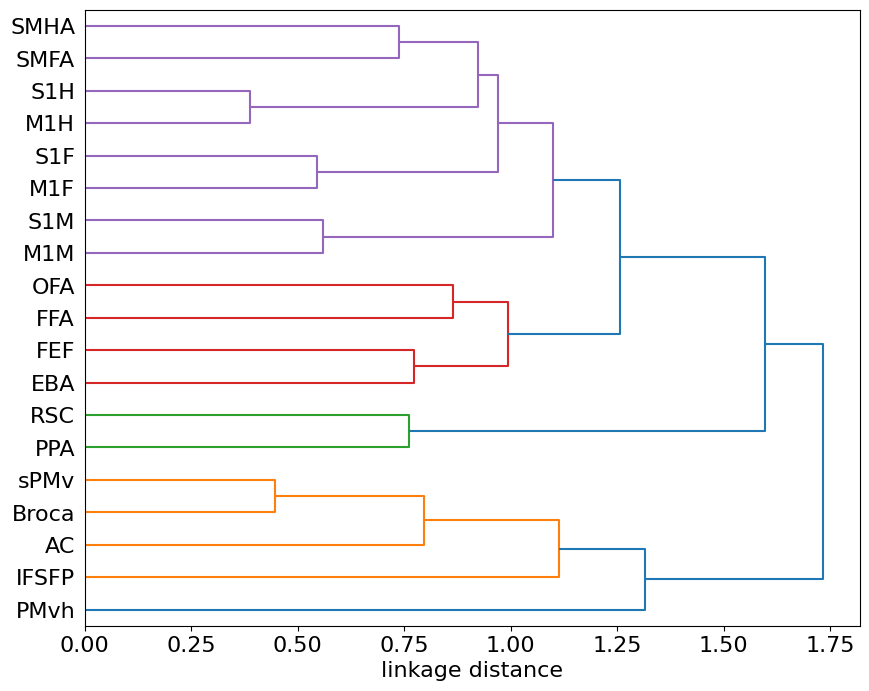

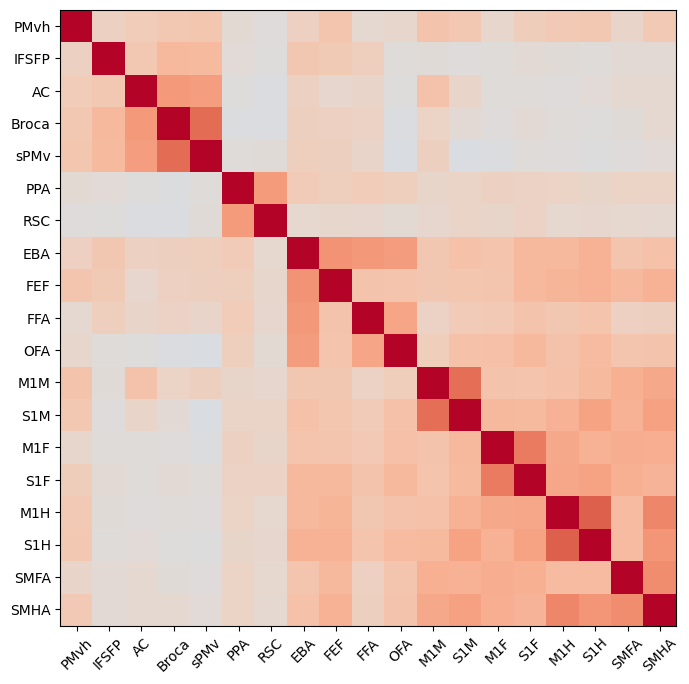

0.15477700504299263
[10  5  0  1 18 11 12  2  3  4  9  8 15  6 13  7 14 16 17]


In [13]:
#roi_corr_matrix_dict[sub] hierarchical culustering
import seaborn as sns
from scipy.cluster import hierarchy

# Initialize a dictionary to store the linkage matrix for each subject
linkage_matrix_dict = {}

# Loop through each subject
for sub in sub_list:
    # Compute the linkage matrix for the hierarchical clustering of the ROI-wise correlation matrix
    linkage_matrix = hierarchy.linkage(roi_corr_matrix_dict[sub], method='average')
    
    # Store the linkage matrix in the dictionary
    linkage_matrix_dict[sub] = linkage_matrix
    
    # Plot the dendrogram of the hierarchical clustering
    plt.figure(figsize=(10, 8))
    dendrogram = hierarchy.dendrogram(linkage_matrix, labels=common_rois, orientation='right')
    plt.title(f"Subject {sub} ROI-wise Correlation Matrix Dendrogram")
    plt.show()                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              
    
    # Plot the reordered mean correlation matrix for the current subject
    plt.figure(figsize=(10, 8))
    roi_order = hierarchy.leaves_list(linkage_matrix)
    mean_corr_matrix_reordered = mean_corr_matrix[roi_order][:, roi_order]
    plt.imshow(mean_corr_matrix_reordered, cmap='coolwarm', vmin=-1, vmax=1)
    plt.colorbar()
    plt.title(f"Reordered Mean Correlation Matrix for Subject {sub}")
    plt.xticks(ticks=np.arange(len(common_rois)), labels=np.array(common_rois)[roi_order], rotation=45)
    plt.yticks(ticks=np.arange(len(common_rois)), labels=np.array(common_rois)[roi_order])
    plt.show()
    print(get_modularity_deterministic(roi_corr_matrix_dict[sub]))

# Compute the linkage matrix for the hierarchical clustering of the mean correlation matrix
mean_linkage_matrix = hierarchy.linkage(mean_corr_matrix, method='average')

# Plot the dendrogram of the hierarchical clustering of the mean correlation matrix
plt.figure(figsize=(10, 8))
dendrogram = hierarchy.dendrogram(mean_linkage_matrix, labels=common_rois, orientation='right')
# plt.title("Mean Correlation Matrix Dendrogram")
plt.xlabel('linkage distance', fontsize=16)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
plt.show()

#replot the mean correlation matrix with the new order
# Compute the order of the ROIs based on the hierarchical clustering
MEAN_roi_order = hierarchy.leaves_list(mean_linkage_matrix)
MEAN_roi_order = [int(i) for i in "10  5  0  1 18 11 12  2  3  4  9  8 15  6 13  7 14 16 17".split(' ')] 

# Reorder the mean correlation matrix based on the hierarchical clustering
mean_corr_matrix_reordered = mean_corr_matrix[MEAN_roi_order][:, MEAN_roi_order]

# Plot the reordered mean correlation matrix
plt.figure(figsize=(8, 8))
plt.imshow(mean_corr_matrix_reordered, cmap='coolwarm', vmin=-1, vmax=1)
# plt.colorbar()
# plt.title("Reordered Mean Correlation Matrix")
plt.xticks(ticks=np.arange(len(common_rois)), labels=np.array(common_rois)[MEAN_roi_order], rotation=45)
plt.yticks(ticks=np.arange(len(common_rois)), labels=np.array(common_rois)[MEAN_roi_order])
plt.savefig(f'./FIGURES/spatiotemporal/LLAMAWHISPERMLP_mean_corr_matrix_reordered.png')
plt.show()
print(get_modularity_deterministic(mean_corr_matrix_reordered))

print(MEAN_roi_order)


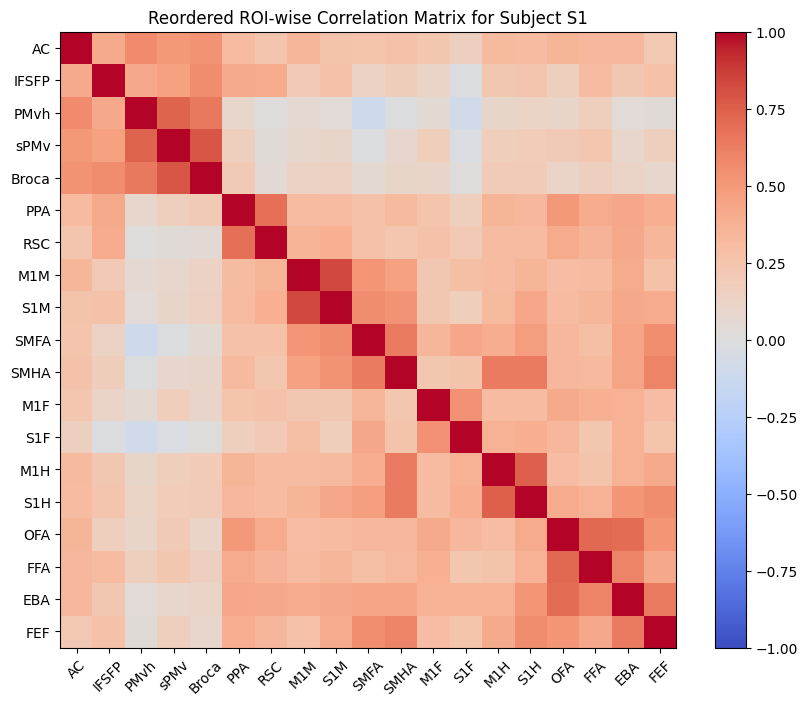

0.123047076028245


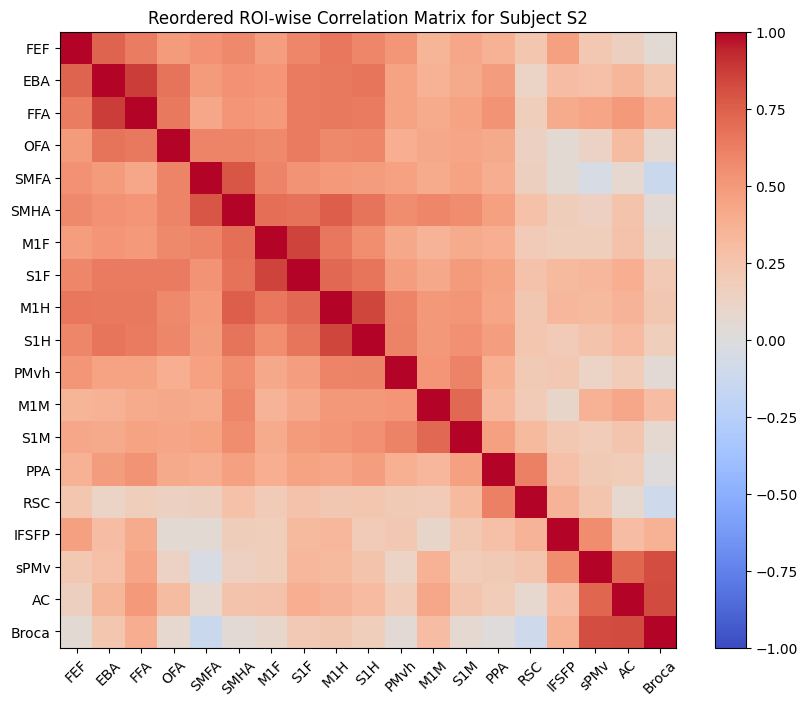

0.06516598439874094


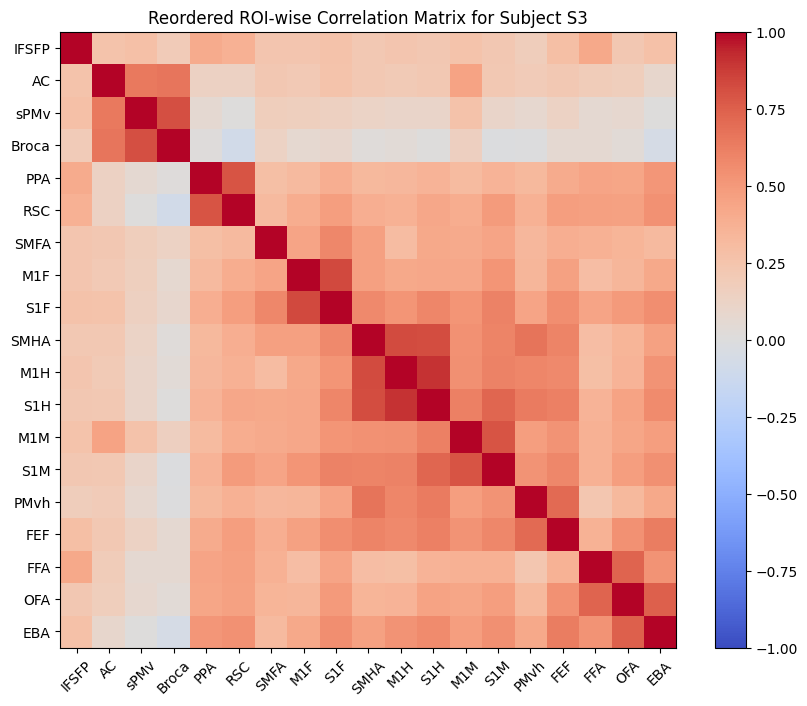

0.07549064147197575


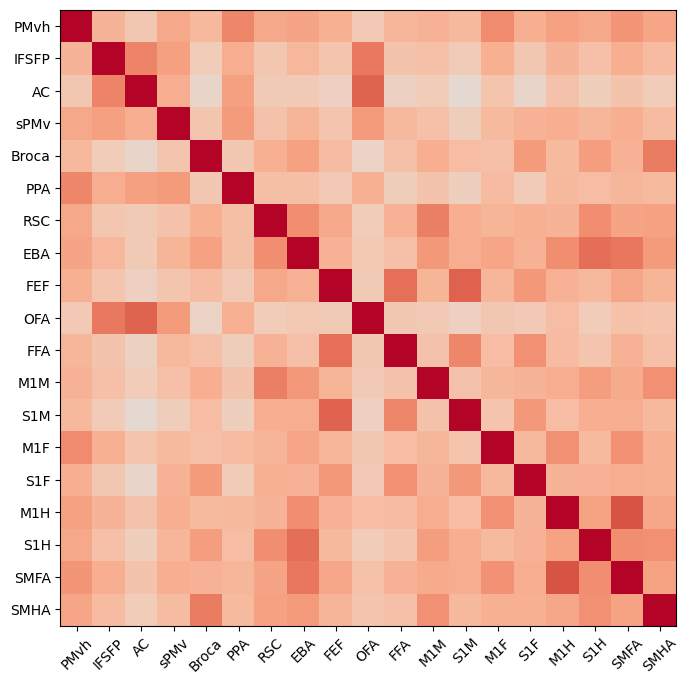

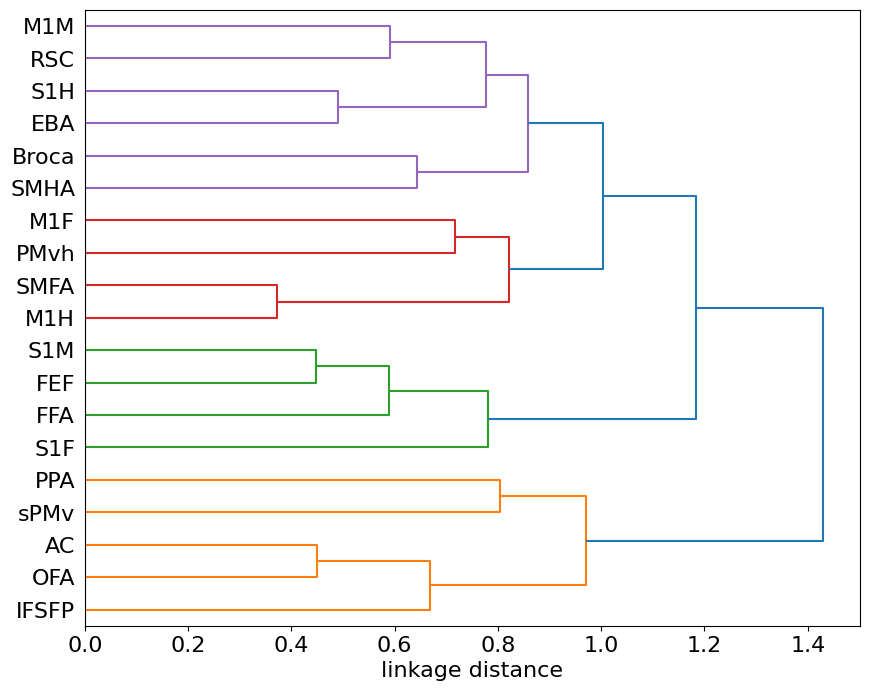

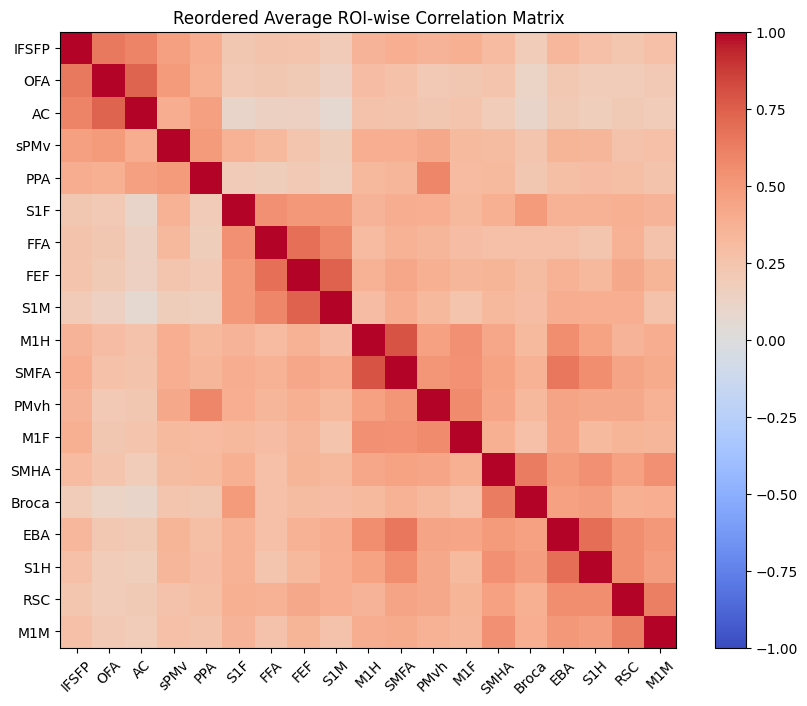

0.06758757531462312
0.39093920714664676 0.1953711172138894


In [27]:
#from roi_all_test_resp_dict_avg, compute the roi x roi correlation matrix for each subject (reordered using the mean_linkage_matrix) (and also one for average subject wise)
import numpy as np
import matplotlib.pyplot as plt

# Initialize a dictionary to store the ROI-wise correlation matrix for each subject
roi_correlation_matrix_dict = {}

# Loop through each subject
for sub in sub_list:
    # Initialize a dictionary to store the ROI-wise correlation matrix for the current subject
    roi_correlation_matrix_dict[sub] = np.zeros((len(common_rois), len(common_rois)))
    
    # Loop through each ROI
    for i, roi1 in enumerate(common_rois):
        # Extract the average responses for the current ROI
        roi1_resp_avg = roi_all_test_resp_dict_avg[sub][roi1]
        
        # Loop through each ROI
        for j, roi2 in enumerate(common_rois):
            # Extract the average responses for the current ROI
            roi2_resp_avg = roi_all_test_resp_dict_avg[sub][roi2]
            
            # Ensure the data is in the correct shape (samples, features)
            if roi1_resp_avg.shape[0] != roi2_resp_avg.shape[0]:
                raise ValueError(f"Shape mismatch between {roi1} and {roi2} for subject {sub}")
            
            # Compute the correlation between the average responses for the current ROIs
            correlation = np.corrcoef(roi1_resp_avg, roi2_resp_avg)[0, 1]
            
            # Store the correlation in the correlation matrix
            roi_correlation_matrix_dict[sub][i, j] = correlation
            
# Plot the ROI-wise correlation matrix for each subject (#roi x #roi) (reordered using the mean_linkage_matrix)
# Initialize a dictionary to store the reordered ROI-wise correlation matrix for each subject
reordered_roi_correlation_matrix_dict = {}

# Loop through each subject
for sub in sub_list:
    # Initialize a dictionary to store the reordered ROI-wise correlation matrix for the current subject
    reordered_roi_correlation_matrix_dict[sub] = np.zeros((len(common_rois), len(common_rois)))
    
    # Get the order of the ROIs based on the hierarchical clustering for the current subject
    roi_order = hierarchy.leaves_list(linkage_matrix_dict[sub])
    
    # Reorder the correlation matrix based on the hierarchical clustering
    reordered_corr_matrix = roi_correlation_matrix_dict[sub][roi_order][:, roi_order]
    
    # Store the reordered correlation matrix in the dictionary
    reordered_roi_correlation_matrix_dict[sub] = reordered_corr_matrix
    
    # Plot the reordered ROI-wise correlation matrix for the current subject
    plt.figure(figsize=(10, 8))
    plt.imshow(reordered_corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
    plt.colorbar()
    plt.title(f"Reordered ROI-wise Correlation Matrix for Subject {sub}")
    plt.xticks(ticks=np.arange(len(common_rois)), labels=np.array(common_rois)[roi_order], rotation=45)
    plt.yticks(ticks=np.arange(len(common_rois)), labels=np.array(common_rois)[roi_order])
    plt.show()
    print(get_modularity_deterministic(reordered_corr_matrix))
    
# Compute the average ROI-wise correlation matrix across subjects
avg_roi_correlation_matrix = np.mean(list(reordered_roi_correlation_matrix_dict.values()), axis=0)

# Plot the average ROI-wise correlation matrix
plt.figure(figsize=(8, 8))
#use MEAN_roi_order
#reorder the avg_roi_correlation_matrix
avg_roi_correlation_matrix_reordered = avg_roi_correlation_matrix[MEAN_roi_order][:, MEAN_roi_order]
plt.imshow(avg_roi_correlation_matrix_reordered, cmap='coolwarm', vmin=-1, vmax=1)
# plt.colorbar()
# plt.title("Average ROI-wise Correlation Matrix Across Subjects")
plt.xticks(ticks=np.arange(len(common_rois)), labels=np.array(common_rois)[MEAN_roi_order], rotation=45)
plt.yticks(ticks=np.arange(len(common_rois)), labels=np.array(common_rois)[MEAN_roi_order])
plt.show()


#plto the same as above, but recompute the MEAN_roi_order using dendrogram of the avg_roi_correlation_matrix
# Compute the linkage matrix for the hierarchical clustering of the average ROI-wise correlation matrix
avg_linkage_matrix = hierarchy.linkage(avg_roi_correlation_matrix, method='average')

# Plot the dendrogram of the hierarchical clustering of the average ROI-wise correlation matrix
plt.figure(figsize=(10, 8))
dendrogram = hierarchy.dendrogram(avg_linkage_matrix, labels=common_rois, orientation='right')
# plt.title("Average ROI-wise Correlation Matrix Dendrogram")
plt.xlabel('linkage distance', fontsize=16)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
plt.show()

# Compute the order of the ROIs based on the hierarchical clustering of the average ROI-wise correlation matrix
new_MEAN_roi_order = hierarchy.leaves_list(avg_linkage_matrix)

# Reorder the average ROI-wise correlation matrix based on the hierarchical clustering
avg_roi_correlation_matrix_reordered = avg_roi_correlation_matrix[new_MEAN_roi_order][:, new_MEAN_roi_order]

# Plot the reordered average ROI-wise correlation matrix
plt.figure(figsize=(10, 8))
plt.imshow(avg_roi_correlation_matrix_reordered, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.title("Reordered Average ROI-wise Correlation Matrix")
plt.xticks(ticks=np.arange(len(common_rois)), labels=np.array(common_rois)[new_MEAN_roi_order], rotation=45)
plt.yticks(ticks=np.arange(len(common_rois)), labels=np.array(common_rois)[new_MEAN_roi_order])
plt.show()

print(get_modularity_deterministic(avg_roi_correlation_matrix_reordered))
print(avg_roi_correlation_matrix_reordered.mean(), avg_roi_correlation_matrix_reordered.std())


# 3. Static, Spatially Averaged Analysis


In [ ]:
#all results already loaded from before
all_results.head()

,exp_info,fromboyhoodtofatherhood_r2_mean,fromboyhoodtofatherhood_r_mean,mean_SPE_mean,mean_SPE_std,mean_cc_max_mean,mean_cc_max_std,mean_cc_norm_mean,mean_cc_norm_std,mean_corrs_unnorm_mean,...,S1_score_paths,S2_score_paths,S3_score_paths,stimulus_setting,encoding_setting,response_setting,name_setting,task,format_name_name,stimulus_setting_2
0,whisper-small_11_default_default-default-defau...,0.026304,0.026304,-0.267177,0.317254,0.412097,0.035575,0.216238,0.036534,0.105114,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,whisper-small_11_default_default,default,default,default,whisper-small_11_default_default-default-default,default,NaN
1,LLAMA7B_4-default-default---default,0.029558,0.029558,-5.271338,0.769489,0.412097,0.035575,0.229077,0.032268,0.114437,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA7B_4,default,default,default,LLAMA7B_4-default-default,default,NaN
2,DSNFT_LLAMA7B_12-singleRNN-LSTM-nli-lo-bi-conc...,0.025989,0.025989,-0.031629,0.078806,0.412097,0.035575,0.179249,0.027713,0.092278,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,DSNFT_LLAMA7B_12,singleRNN-LSTM-nli-lo-bi-conc_1_1_4_none_256,PCA_256,validation_method CV loss_criteria MAE,DSNFT_LLAMA7B_12-singleRNN-LSTM-nli-lo-bi-conc...,validation_method__CV-loss_criteria__MAE,NaN
3,whisper-large_20_1000_default-default-default-...,0.015545,0.015545,-3.416734,2.515976,0.412097,0.035575,0.146569,0.031844,0.071661,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,whisper-large_20_1000_default,default,default,default,whisper-large_20_1000_default-default-default,default,NaN
4,DSNFT_LLAMA7B_12-singleRNN-LSTM-li-lo-bi-conc_...,0.026910,0.026910,-0.056502,0.135634,0.412097,0.035575,0.178878,0.026863,0.091958,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,DSNFT_LLAMA7B_12,singleRNN-LSTM-li-lo-bi-conc_1_1_4_256_256,PCA_256,validation_method CV loss_criteria MAE,DSNFT_LLAMA7B_12-singleRNN-LSTM-li-lo-bi-conc_...,validation_method__CV-loss_criteria__MAE,NaN


In [13]:
all_results[all_results['stimulus_setting']=="LLAMA30B_18"][['exp_info','mean_r2_mean','onapproachtopluto_r_mean','wheretheressmoke_r_mean','fromboyhoodtofatherhood_r_mean']]

,exp_info,mean_r2_mean,onapproachtopluto_r_mean,wheretheressmoke_r_mean,fromboyhoodtofatherhood_r_mean
625,LLAMA30B_18__whisper-large_final_default_defau...,0.041056,0.037940,0.050492,0.050172
431,LLAMA30B_18-default-default---default,0.036746,0.035148,0.046429,0.045543


In [5]:
#sort by mean_r2_mean 
all_results.sort_values(by = 'mean_r2_mean', ascending = False, inplace = True)
#filter for stimulus setting that is "DSNFT"
new_df= all_results[all_results['exp_info'].str.contains("DSNFT")]
print(new_df.shape)
new_df.head(40)[['stimulus_setting', 'stimulus_setting_2','encoding_setting','response_setting','mean_r2_mean','mean_cc_norm_mean']]


#do the thing above, but with encoding setting that has MLP_*,* format
# all_results.sort_values(by = 'mean_r2_mean', ascending = False, inplace = True)
# new_df = all_results[all_results['encoding_setting'].str.contains("MLP")]
# new_df = new_df[new_df['encoding_setting'].str.contains(r"MLP.*_.*_.*")]
# new_df.head(100)[['stimulus_setting', 'stimulus_setting_2','encoding_setting','response_setting','mean_r2_mean','mean_cc_norm_mean']]

(178, 29)


,stimulus_setting,stimulus_setting_2,encoding_setting,response_setting,mean_r2_mean,mean_cc_norm_mean
385,DSNFT_LLAMA7B_12,NaN,singleRNN-LSTM-nli-lo-bi-weip_1_1_4_none_768,PCA_512,0.033266,0.269525
688,DSNFT_LLAMA7B_12,NaN,singleRNN-LSTM-nli-lo-bi-weip_1_1_4_none_768,PCA_1024,0.033084,0.260709
505,DSNFT_LLAMA7B_12,NaN,singleRNN-LSTM-nli-lo-bi-weip_1_1_4_none_512,PCA_256,0.032823,0.269741
618,DSNFT_LLAMA7B_12,NaN,singleRNN-LSTM-nli-lo-bi-weip_1_1_4_none_1024,PCA_512,0.032154,0.253210
594,DSNFT_LLAMA7B_12,NaN,singleRNN-GRU-nli-lo-bi-weip_1_1_4_none_512,PCA_256,0.032068,0.261510
63,DSNFT_LLAMA7B_12,NaN,singleRNN-LSTM-nli-lo-bi-weip_1_1_4_none_256,PCA_512,0.031775,0.267490
140,DSNFT_LLAMA7B_12,NaN,singleRNN-LSTM-nli-lo-bi-weip_1_1_4_none_512,PCA_512,0.031567,0.252950
682,DSNFT_LLAMA7B_12,NaN,singleRNN-LSTM-nli-lo-bi-weip_1_1_4_none_256,PCA_256,0.031061,0.266370
647,DSNFT_LLAMA7B_12,NaN,singleRNN-LSTM-nli-lo-bi-weip_1_1_4_none_768,PCA_256,0.030927,0.253470
162,DSNFT_LLAMA7B_12,NaN,singleRNN-LSTM-nli-lo-bi-last_1_1_4_none_256,PCA_256,0.030254,0.256156


## 3.1. Looking at Best in Each Condition (Hyperparemter already done)


### 3.1.1. Analyis : Overall Variance Partitioning (not recommended, should use voxel-wise variance partitioning)


In [7]:
def get_audio_semantic_mixed_r2_from_df(df, audio = 'whisper-large_final_default_default', semantic = 'LLAMA7B_12'):
    audio_df = df[(df['stimulus_setting'] == audio) & (df['stimulus_setting_2'].isna())]
    semantic_df = df[(df['stimulus_setting'] == semantic) & (df['stimulus_setting_2'].isna())]
    multi_df = df[(df['stimulus_setting'] == semantic) & (df['stimulus_setting_2'] == audio)]
    return audio_df['mean_r2_mean'].mean(), semantic_df['mean_r2_mean'].mean(), multi_df['mean_r2_mean'].mean()


enc_setting_pttrn_list = ['default', 'PCA', 'reducedLinear_(\d+)', 'MLP_(\d+)']

for encoding_setting_pttrn in enc_setting_pttrn_list:
    df = best_models[best_models['encoding_setting'].str.contains(encoding_setting_pttrn)]
    audior2, semanticr2, multir2 = get_audio_semantic_mixed_r2_from_df(df)
    intersection_r2 = audior2 + semanticr2 - multir2
    print(f"====encoding setting : {encoding_setting_pttrn}====\n\n audio and semantic : {intersection_r2:.2%}, audio only : {audior2-intersection_r2:.2%}, semantic only : {semanticr2-intersection_r2:.2%}, multi : {multir2:.2%}\n")
    
    
    print(get_audio_semantic_mixed_r2_from_df(df)) 
    

====encoding setting : default====

 audio and semantic : 2.42%, audio only : 0.37%, semantic only : 1.20%, multi : 3.98%

(0.0278816255178218, 0.03611239374349485, 0.039843952027633495)
====encoding setting : PCA====

 audio and semantic : nan%, audio only : nan%, semantic only : nan%, multi : nan%

(nan, nan, nan)
====encoding setting : reducedLinear_(\d+)====

 audio and semantic : 2.46%, audio only : 0.43%, semantic only : 1.21%, multi : 4.10%

(0.0288929109828073, 0.0366955941825213, 0.0410065835895563)
====encoding setting : MLP_(\d+)====

 audio and semantic : nan%, audio only : nan%, semantic only : nan%, multi : nan%

(nan, nan, nan)


/tmp/ipykernel_376847/328689587.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df = best_models[best_models['encoding_setting'].str.contains(encoding_setting_pttrn)]


### 3.1.2. Table 1. Best Model Performance

In [8]:
all_results.sort_values('mean_r2_mean', ascending = False).head(20)[['encoding_setting', 'stimulus_setting', 'stimulus_setting_2', 'mean_r2_mean']]

,encoding_setting,stimulus_setting,stimulus_setting_2,mean_r2_mean
302,MLPTanh_256,LLAMA7B_12,whisper-large_final_default_default,0.042882
67,MLPTanh_256,LLAMA7B_12,whisper-large_32_default_default,0.042874
281,MLP_256,LLAMA7B_12,whisper-large_final_default_default,0.042768
700,MLP_256,LLAMA7B_12,whisper-large_32_default_default,0.042695
689,"MultimodalMLPTanh_16384,5120_1_256",LLAMA7B_12,whisper-large_final_default_default,0.041825
290,reducedLinear_512,LLAMA7B_12,whisper-large_final_default_default,0.041637
634,MLPTanh_256,LLAMA7B_12,whisper-large_24_default_default,0.041562
264,MLPTanh_256,LLAMA7B_16,whisper-large_32_default_default,0.041552
301,reducedLinear_512,LLAMA7B_12,whisper-large_final_default_default,0.041540
95,"MultimodalMLPTanh_16384,5120_1_64",LLAMA7B_12,whisper-large_final_default_default,0.041516


In [9]:
pd.set_option('display.max_colwidth', None)  # None means display full column width


to_see = best_models.loc[:,['stimulus_setting','stimulus_setting_2','encoding_setting','response_setting','mean_r2_mean', 'mean_cc_norm_mean']]
#in encoding_setting, default should be written as "full voxels"
#also in stimulus settings LLAMA7B_12 should be semantic, and whisper-large_final_default_default should be audio
#also, the mena_r2_mean and mean_cc_norm_mean should be rounded to 2 decimal points
#also, stimulus_setting_2 should also be made (NaN : don't touch, but if it's there, it should be "audio")


to_see['response_setting'] = to_see['response_setting'].apply(lambda x: "full voxels" if x == "default" else x)
to_see['stimulus_setting'] = to_see['stimulus_setting'].apply(lambda x: "semantic" if x == "LLAMA7B_12" else "audio")
to_see['stimulus_setting_2'] = to_see['stimulus_setting_2'].apply(lambda x: "audio" if x == "whisper-large_final_default_default" else x)
to_see['mean_r2_mean'] = to_see['mean_r2_mean'].apply(lambda x: f"{round(x * 100, 2)}%")
to_see['mean_cc_norm_mean'] = to_see['mean_cc_norm_mean'].apply(lambda x: f"{round(x * 100, 2)}%")
to_see['encoding_setting'] = to_see['encoding_setting'].str.replace(r"reducedLinear_\d+", "ReLinear", regex=True)
to_see['response_setting'] = to_see['response_setting'].str.replace(r'PCA_\d+', 'PCA', regex=True)

# Sort the DataFrame by 'stimulus_setting' and 'stimulus_setting_2'
to_see = to_see.sort_values(by=['mean_r2_mean'], ascending=False)
to_see = to_see.sort_values(by=['stimulus_setting', 'stimulus_setting_2'], ascending=False)
# Display the sorted DataFrame
to_see

#TODO : also write the percentage wise increases! (using excel!)


,stimulus_setting,stimulus_setting_2,encoding_setting,response_setting,mean_r2_mean,mean_cc_norm_mean
302,semantic,audio,MLPTanh_256,PCA,4.29%,34.32%
689,semantic,audio,"MultimodalMLPTanh_16384,5120_1_256",PCA,4.18%,32.59%
46,semantic,audio,ReLinear,PCA,4.1%,32.41%
629,semantic,audio,default,full voxels,4.1%,31.36%
229,semantic,audio,default,PCA,3.87%,28.92%
319,semantic,NaN,MLPTanh_256,PCA,3.79%,30.89%
611,semantic,NaN,ReLinear,PCA,3.67%,29.95%
132,semantic,NaN,default,full voxels,3.66%,29.12%
722,semantic,NaN,default,PCA,3.56%,26.88%
28,audio,NaN,MLPTanh_256,PCA,3.01%,29.01%


## 3.2. Plotting how changes in one affects performance

### 3.2.0 Setting Up

In [10]:
from utils_perf_df import analyze_custom_settings_combinations, filter_sort_and_convert_to_numeric
from utils_plotter import plot_baseline_value
import matplotlib.pyplot as plt

columns_of_interest = [ 'mean_cc_norm_mean', 'mean_cc_norm_std', 'mean_r2_mean', 'mean_r2_std', 'stimulus_setting', 'stimulus_setting_2', 'encoding_setting', 'response_setting', 'format_name_name'] #, 'name_setting', 'task', 'format_name_name'] 'exp_info',

final_results = all_results[columns_of_interest]
final_results = final_results.reset_index(drop = True)
final_results = final_results[final_results['format_name_name'].str.contains('loss_criteria__MAE|default')]

settings_list = ['stimulus_setting', 'encoding_setting', 'response_setting', 'stimulus_setting_2']
results = analyze_custom_settings_combinations(final_results, settings_list)

# To display or process the results
# for key, value in results.items():
#     print(key)
#     for group_key, group_df in value.items():
#         print(f"  Group {group_key} with {len(group_df)} entries")
#         # Here you can save, display or further analyze group_df

### 3.2.1. Training data/model size variations and performance (linear encoder)

In [11]:
model2name_dict = {
    "LLAMA7B" : "LLAMA 7B",
    "LLAMA27Bhf" : "LLAMA-2 7B",
    "LLAMA38B" : "LLAMA-3 8B",
    "LLAMA13B" : "LLAMA 13B", 
    "LLAMA30B" : "LLAMA 33B",
    "LLAMA65B" : "LLAMA 65B",    
    'whisper-large_(\d+|\w+)+_default_default' : 'whisper-large',
    'whisper-large-v2_(\d+|\w+)_default_default' : 'whisper-large-v2',
    'whisper-large-v3_(\d+|\w+)_default_default' : 'whisper-large-v3',
    'whisper-tiny_(\d+|\w+)+_default_default' : 'whisper-tiny', 
    'whisper-small_(\d+|\w+)_default_default' : 'whisper-small', 
    'whisper-base_(\d+|\w+)_default_default' : 'whisper-base', 
}

def extra_plot_settings(title, xlim, ylim, criteria, xlabel = "Normalized Layer Depth",ylabel = "Encoder Performance (Avg $r^2$)", fontsize = 14, **kwargs) : 
    plt.xlabel(xlabel, fontsize = fontsize)   
    plt.ylabel(ylabel, fontsize = fontsize)   
    plt.title(title, fontsize = fontsize)
    plt.xlim(xlim)
    plt.ylim(ylim)
    
    plt.xticks(fontsize=fontsize)
    plt.yticks(fontsize=fontsize)
    plt.legend(fontsize = fontsize)
    plot_baseline_value(criteria, **kwargs)


/tmp/ipykernel_376847/3400227866.py:38: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df = df[df['stimulus_setting'].str.contains(r'^' + model, na=False)]


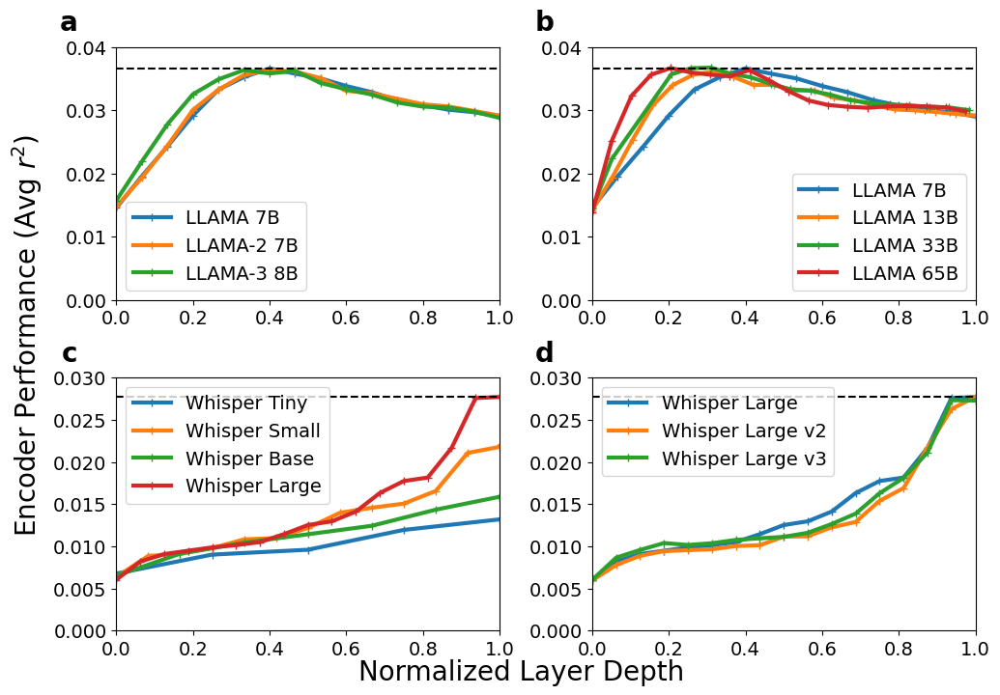

In [12]:
import matplotlib.pyplot as plt

# Define the model to name dictionary
model2name_dict = {
    "LLAMA7B": "LLAMA 7B",
    "LLAMA13B": "LLAMA 13B",
    "LLAMA30B": "LLAMA 33B",
    "LLAMA65B": "LLAMA 65B",
    "LLAMA27Bhf": "LLAMA-2 7B",
    "LLAMA38B": "LLAMA-3 8B",
    "whisper-tiny_(\\d+|\\w+)+_default_default": "Whisper Tiny",
    "whisper-small_(\\d+|\\w+)_default_default": "Whisper Small",
    "whisper-base_(\\d+|\\w+)_default_default": "Whisper Base",
    "whisper-large_(\\d+|\\w+)+_default_default": "Whisper Large",
    "whisper-large-v2_(\\d+|\\w+)_default_default": "Whisper Large v2",
    "whisper-large-v3_(\\d+|\\w+)_default_default": "Whisper Large v3"
}

# Define the criteria and x-axis
criteria = 'mean_r2_mean'
x_axis = 'stimulus_setting'

# Function to apply extra plot settings
def extra_plot_settings(ax, title, xlim, ylim, criteria, xlabel="Normalized Layer Depth", ylabel="Encoder Performance (Avg $r^2$)", fontsize=16, **kwargs):
    ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize)
    ax.set_title(title, fontsize=fontsize)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.tick_params(axis='both', labelsize=fontsize)
    ax.legend(fontsize=fontsize)
    plot_baseline_value(criteria, ax_or_plt=ax, **kwargs)

# Function to plot data for given models
def plot_models(ax, models, title, xlabel, ylabel, xlim, ylim, fontsize = 14, **kwargs):
    for model in models:
        df = results['encoding_setting__response_setting'][("default", "default")]
        df = df[df['stimulus_setting'].str.contains(r'^' + model, na=False)]
        numerized_df = filter_sort_and_convert_to_numeric(df, {}, multimodal=False, sort_by=x_axis,
                                                          colunmns2convert=['stimulus_setting'])
        ax.plot(numerized_df[x_axis] / (NUM_LAYERS_DICT[model.split('_')[0]] - 1), numerized_df[criteria], label=model2name_dict[model], marker='+', linewidth=3)
    extra_plot_settings(ax, title, xlim, ylim, criteria, xlabel, ylabel, fontsize = fontsize, **kwargs)

# Create a 2x2 grid of subplots
# fig, axs = plt.subplots(2, 2, figsize=(15, 10))
fig, axs = plt.subplots(2, 2, figsize=(10, 7))

# Plot LLAMA7B version variations in the first row
plot_models(axs[0, 0], ["LLAMA7B", "LLAMA27Bhf", "LLAMA38B"], None, None, None, (0, 1), (0, 0.04))
plot_models(axs[0, 1], ["LLAMA7B", "LLAMA13B", "LLAMA30B", "LLAMA65B"], None, None, None, (0, 1), (0, 0.04))

# Plot Whisper version variations in the second row
plot_models(axs[1, 0], ['whisper-tiny_(\\d+|\\w+)+_default_default', 'whisper-small_(\\d+|\\w+)_default_default', 'whisper-base_(\\d+|\\w+)_default_default','whisper-large_(\\d+|\\w+)+_default_default'], None, None, None, (0, 1), (0, 0.03), whisper=True)
plot_models(axs[1, 1], ['whisper-large_(\\d+|\\w+)+_default_default', 'whisper-large-v2_(\\d+|\\w+)_default_default', 'whisper-large-v3_(\\d+|\\w+)_default_default'], None, None, None , (0, 1), (0, 0.03), whisper=True)

# Add labels (a, b, c, d) on top of each subplot
labels = ['a', 'b', 'c', 'd']
for i, ax in enumerate(axs.flat):
    ax.text(-0.1, 1.15, labels[i], transform=ax.transAxes, fontsize=20, fontweight='bold', va='top', ha='right')


# Adjust layout
plt.tight_layout()
# fig.suptitle("Encoder Performance vs. Normalized Layer Depth", fontsize=25, y=1.10)
# Add common x-label and y-label
fig.text(0.5, -0.01, 'Normalized Layer Depth', ha='center', fontsize=20)
fig.text(-0.03, 0.5, 'Encoder Performance (Avg $r^2$)', va='center', rotation='vertical', fontsize=20)

plt.savefig('./FIGURES/scaling_figure.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
##kept for reference!

'''
##varying whisper settings and stuff 
criteria = 'mean_r2_mean' #'mean_r2_mean' #'mean_cc_norm_mean'

x_axis = 'stimulus_setting'

for model in ['whisper-tiny_(\d+|\w+)+_default_default', 'whisper-small_(\d+|\w+)_default_default', 'whisper-base_(\d+|\w+)_default_default', 'whisper-large_(\d+|\w+)+_default_default'] : 
    df = results['encoding_setting__response_setting'][("default", "default" )]
    df = df[df['stimulus_setting'].str.contains(r'^' + model, na=False)]
    print(model)
    numerized_df = filter_sort_and_convert_to_numeric(df, {}, multimodal=False,sort_by= x_axis,
                                                  colunmns2convert=['stimulus_setting'])
    plt.plot(numerized_df[x_axis]/(NUM_LAYERS_DICT[model.split('_')[0]]-1), numerized_df[criteria], label=model2name_dict[model], marker='+')

extra_plot_settings(None, (0,1), (0,0.03), criteria,whisper = True)
# plt.title(f'Varying Whisper Large versions and depth') 
# '''

'\n##varying whisper settings and stuff \ncriteria = \'mean_r2_mean\' #\'mean_r2_mean\' #\'mean_cc_norm_mean\'\n\nx_axis = \'stimulus_setting\'\n\nfor model in [\'whisper-tiny_(\\d+|\\w+)+_default_default\', \'whisper-small_(\\d+|\\w+)_default_default\', \'whisper-base_(\\d+|\\w+)_default_default\', \'whisper-large_(\\d+|\\w+)+_default_default\'] : \n    df = results[\'encoding_setting__response_setting\'][("default", "default" )]\n    df = df[df[\'stimulus_setting\'].str.contains(r\'^\' + model, na=False)]\n    print(model)\n    numerized_df = filter_sort_and_convert_to_numeric(df, {}, multimodal=False,sort_by= x_axis,\n                                                  colunmns2convert=[\'stimulus_setting\'])\n    plt.plot(numerized_df[x_axis]/(NUM_LAYERS_DICT[model.split(\'_\')[0]]-1), numerized_df[criteria], label=model2name_dict[model], marker=\'+\')\n\nextra_plot_settings(None, (0,1), (0,0.03), criteria,whisper = True)\n# plt.title(f\'Varying Whisper Large versions and depth\') \n

### 3.2.2. MLP vs Linear by depth (LLAMA7B) and multimdoal depth combinations 

In [14]:
# MLP_variation_df = results['encoding_setting__response_setting'][('MLP_256', 'PCA_512')]
MLP_variation_df = results['encoding_setting__response_setting'][('MLPTanh_256', 'PCA_512')] #Tanh  Version

#MLPs
multimodal_MLP_df = MLP_variation_df[MLP_variation_df['stimulus_setting_2'].str.contains(r'whisper-large_(\d+)_default_default', na=False)]
whisper_MLP_df = MLP_variation_df[MLP_variation_df['stimulus_setting'].str.contains(r'whisper-large_(\d+)_default_default', na=False)]
LLAMA7B_MLP_df = MLP_variation_df[MLP_variation_df['stimulus_setting'].str.contains('LLAMA7B_', na=False)]
LLAMA7B_MLP_df = LLAMA7B_MLP_df[LLAMA7B_MLP_df['stimulus_setting_2'].isna()]

#defaults
default_variation_df = results['encoding_setting__response_setting'][("default", "default")]
LLAMA7B_default_df = default_variation_df[default_variation_df['stimulus_setting'].str.contains('LLAMA7B_', na=False)]
whisper_default_df = default_variation_df[default_variation_df['stimulus_setting'].str.contains('whisper-large_(\\d+|\\w+)+_default_default', na=False)]




/tmp/ipykernel_376847/2063877365.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  multimodal_MLP_df = MLP_variation_df[MLP_variation_df['stimulus_setting_2'].str.contains(r'whisper-large_(\d+)_default_default', na=False)]
/tmp/ipykernel_376847/2063877365.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  whisper_MLP_df = MLP_variation_df[MLP_variation_df['stimulus_setting'].str.contains(r'whisper-large_(\d+)_default_default', na=False)]
/tmp/ipykernel_376847/2063877365.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  whisper_default_df = default_variation_df[default_variation_df['stimulus_setting'].str.contains('whisper-large_(\\d+|\\w+)+_default_default', na=False)]


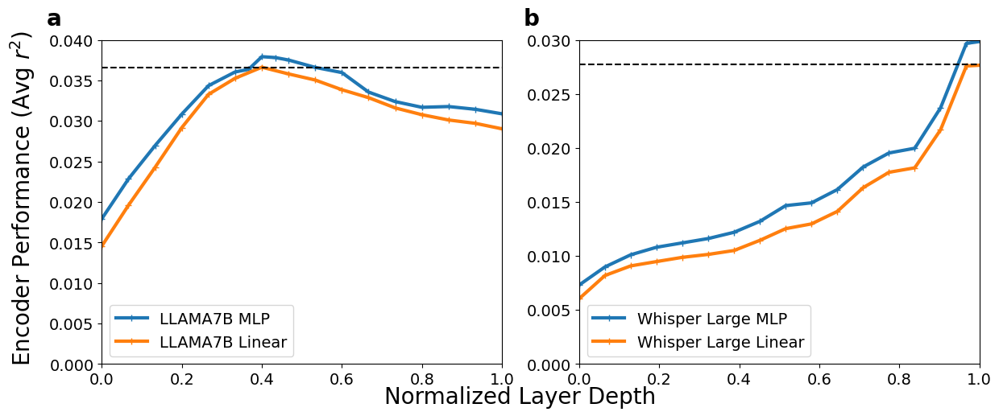

In [15]:
##plotting the MLP vs Linear, unimodality

def plot_models_simple(ax, title, xlabel, ylabel, xlim, ylim, model_df_dict, fontsize = 14, **kwargs):
    for model_name, model_df in model_df_dict.items(): 
        numerized_df = filter_sort_and_convert_to_numeric(model_df, {}, multimodal=False, sort_by=x_axis,
                                                            colunmns2convert=['stimulus_setting'])
        if 'Whisper' in model_name:
            num = 32-1
        else : 
            num = 32-1-1
        ax.plot(numerized_df[x_axis] / num, numerized_df[criteria], label=model_name, marker='+', linewidth=3)
        #TODO : must change "model" here! 
        #32-1 cuz 32 layers for both models 
    extra_plot_settings(ax, title, xlim, ylim, criteria, xlabel, ylabel, fontsize = 14, **kwargs)

# Create a 2x2 grid of subplots
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
# fig, axs = plt.subplots(1, 2, figsize=(8, 3))

# Plot LLAMA7B version variations in the first row
plot_models_simple(axs[0], None, None, None, (0, 1), (0, 0.04), model_df_dict =  {'LLAMA7B MLP': LLAMA7B_MLP_df, 'LLAMA7B Linear' : LLAMA7B_default_df})
plot_models_simple(axs[1], None, None, None, (0, 1), (0, 0.03), model_df_dict =  {'Whisper Large MLP': whisper_MLP_df, 'Whisper Large Linear' : whisper_default_df}, whisper = True)

# Add labels (a, b, c, d) on top of each subplot
labels = ['a', 'b']
for i, ax in enumerate(axs.flat):
    ax.text(-0.1, 1.1, labels[i], transform=ax.transAxes, fontsize=20, fontweight='bold', va='top', ha='right')

# Adjust layout
plt.tight_layout()
# fig.suptitle("Encoder Performance vs. Normalized Layer Depth", fontsize=25, y=1.10)
# Add common x-label and y-label
fig.text(0.5, -0.01, 'Normalized Layer Depth', ha='center', fontsize=20)
fig.text(-0.03, 0.5, 'Encoder Performance (Avg $r^2$)', va='center', rotation='vertical', fontsize=20)

plt.savefig('./FIGURES/MLP_layerwise.png', dpi=300, bbox_inches='tight')
plt.show()

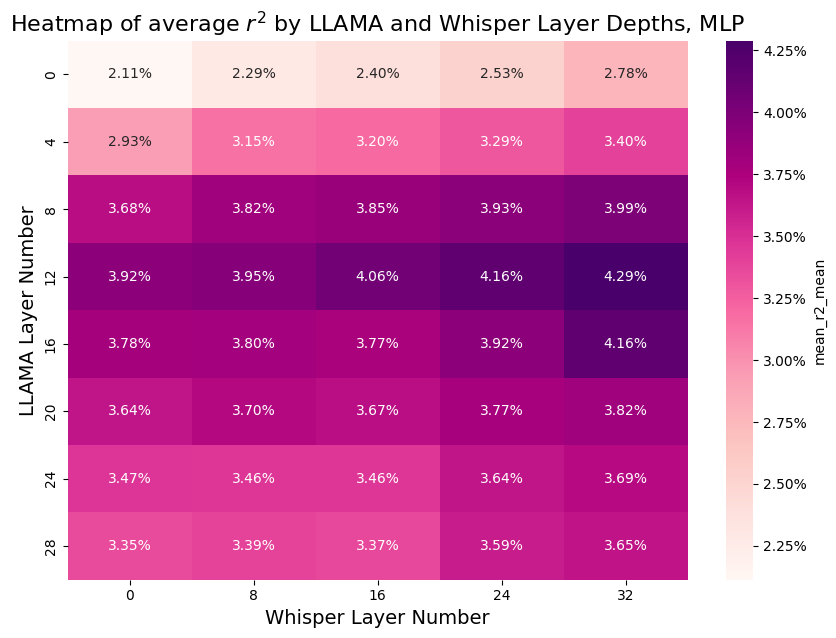

In [16]:
numerized_df = filter_sort_and_convert_to_numeric(multimodal_MLP_df, {}, exclude_condition = None, multimodal = True, sort_by = 'stimulus_setting', colunmns2convert=['stimulus_setting', 'stimulus_setting_2'])
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Assuming numerized_df already has the extracted layer depths and is numeric
# Pivot the DataFrame to create a matrix for the heatmap
heatmap_data = numerized_df.pivot_table(index='stimulus_setting', columns='stimulus_setting_2', values='mean_r2_mean')

# Plot the heatmap
plt.figure(figsize=(10, 7))
ax = sns.heatmap(heatmap_data, annot=True, cmap='RdPu', cbar_kws={'label': 'mean_r2_mean'}, fmt=".2%")

# Format the colorbar to display percentages
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_major_formatter(PercentFormatter(1))

plt.title('Heatmap of average $r^2$ by LLAMA and Whisper Layer Depths, MLP',fontsize=16)
plt.xlabel('Whisper Layer Number', fontsize=14)
plt.ylabel('LLAMA Layer Number', fontsize=14)
plt.savefig('./FIGURES/multimodal_heatmap_RELU_mustredo.png', dpi=300, bbox_inches='tight')
plt.show()



### 3.2.3. Misc. Things 

/tmp/ipykernel_376847/521889375.py:27: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df = df[df['stimulus_setting'].str.contains(r'^' + model, na=False)]


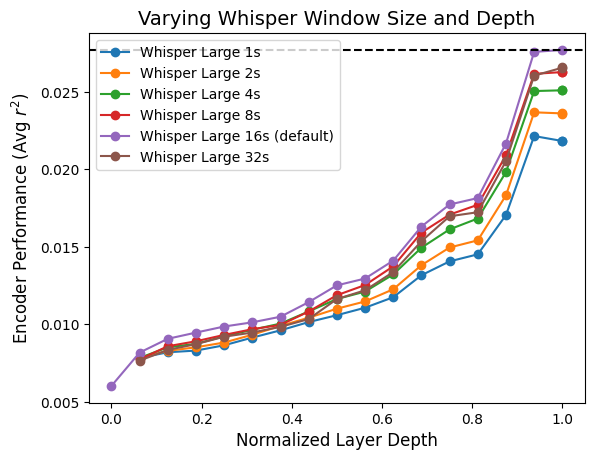

In [24]:
import matplotlib.pyplot as plt

# Define the criteria and x-axis
criteria = 'mean_r2_mean'  # 'mean_r2_mean' or 'mean_cc_norm_mean'
x_axis = 'stimulus_setting'

# Define the model to name dictionary
model2name_dict = {
    'whisper-large_(\\d+|\\w+)+_1000_default': 'Whisper Large 1s',
    'whisper-large_(\\d+|\\w+)+_2000_default': 'Whisper Large 2s',
    'whisper-large_(\\d+|\\w+)+_4000_default': 'Whisper Large 4s',
    'whisper-large_(\\d+|\\w+)+_8000_default': 'Whisper Large 8s',
    'whisper-large_(\\d+|\\w+)+_default_default': 'Whisper Large 16s (default)',
    'whisper-large_(\\d+|\\w+)+_32000_default': 'Whisper Large 32s'
}

# Loop through the models and plot the data
for model in [
    'whisper-large_(\\d+|\\w+)+_1000_default',
    'whisper-large_(\\d+|\\w+)+_2000_default',
    'whisper-large_(\\d+|\\w+)+_4000_default',
    'whisper-large_(\\d+|\\w+)+_8000_default',
    'whisper-large_(\\d+|\\w+)+_default_default',
    'whisper-large_(\\d+|\\w+)+_32000_default'
]:
    df = results['encoding_setting__response_setting'][("default", "default")]
    df = df[df['stimulus_setting'].str.contains(r'^' + model, na=False)]
    numerized_df = filter_sort_and_convert_to_numeric(
        df, {}, multimodal=False, sort_by=x_axis,
        colunmns2convert=['stimulus_setting']
    )

    plt.plot(
        numerized_df[x_axis] / (NUM_LAYERS_DICT[model.split('_')[0]] - 1),
        numerized_df[criteria],
        label=model2name_dict[model],
        marker='o'
    )

# Set the plot title and labels with modified font sizes
plt.title('Varying Whisper Window Size and Depth', fontsize=14)
plt.xlabel('Normalized Layer Depth', fontsize=12)
plt.ylabel('Encoder Performance (Avg $r^2$)', fontsize=12)
plt.legend(loc='upper left', fontsize=10)

# Optional: Set the x-scale to logarithmic if needed
# plt.xscale('log')

# Optional: Adjust the rotation of x-ticks if needed
# plt.xticks(rotation=60)

# Plot the baseline value
plot_baseline_value(criteria, whisper=True)

# Save the figure
plt.savefig('./FIGURES/whisper_window_size.png', dpi=300, bbox_inches='tight')
plt.show()

In [18]:
print(numerized_df['mean_cc_norm_std']/numerized_df['mean_cc_norm_mean'])
print(numerized_df['mean_r2_std']/numerized_df['mean_r2_mean'])


44     0.214030
397    0.223986
8      0.215927
448    0.230340
248    0.206631
283    0.223186
611    0.228662
719    0.227687
340    0.206768
35     0.197708
83     0.209211
42     0.193880
333    0.198278
573    0.178692
147    0.168827
558    0.182823
591    0.180338
dtype: float64
44     0.229379
397    0.243493
8      0.229425
448    0.236471
248    0.221657
283    0.231966
611    0.220811
719    0.246765
340    0.249801
35     0.264121
83     0.283270
42     0.315104
333    0.317066
573    0.321728
147    0.332589
558    0.326904
591    0.326825
dtype: float64


Background RRGGBBAA: ffffff00
Area 0:0:2587.36:1024 exported to 1941 x 768 pixels (72 dpi)
Background RRGGBBAA: ffffff00
Area 0:0:2587.36:1024 exported to 1941 x 768 pixels (72 dpi)
(a) mult SepMLP - mult linear flatmap
(b) mult MLP - mult SepMLP flatmap


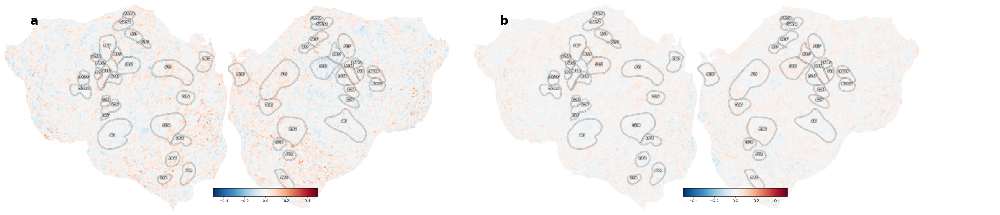

In [27]:
#TODO : 1. REMOVE ROIS!! 2. Do full 3D Plots, 3. Plot timewsise! 4. Mark the voxels that were used!!  5. remove colorbar, and set a common colorbar?

# 5. PLOT5 : 1D voxelwise, pycortex simple plots
vmin = -0.5
vmax = 0.5

#1. Save flatmaps as PNGs (should skip if already done)
#check if png file already exists, and if it does, skip the first for loop
for key, value in nonlinear_improvmenet_dict.items():
    if value.min() < vmin or value.max() > vmax:
        print(f"Warning: {key} has values outside the range [{vmin}, {vmax}].")
    
    # Generate the cortex.Volume object
    vol = get_pycortex_vol(value, vmin=vmin, vmax=vmax)
    
    # Define the filename to save the PNG for each subplot
    fname = f'./FIGURES/{sub}_{key}_flatmap.png'
    
    # Export the flatmap as an image and save it
    cortex.quickflat.make_png(fname, vol, height=768,   
                              with_colorbar=True, with_rois=True, with_labels=True) #with colorbar and rois false for aesthetic

#2. Plotting the saved PNGs in subplots
num_plots = 2  # Only plot two subplots
fig, axes = plt.subplots(1, 2, figsize=(24, 12))  # Adjust to 1x2 grid for 2 subplots

# Flatten the axes array for easy iteration
axes = axes.flatten()

# Load and display saved PNGs without titles
for i, (ax, key) in enumerate(zip(axes, list(nonlinear_improvmenet_dict.keys())[:num_plots])):
    fname = f'./FIGURES/{sub}_{key}_flatmap.png'
    img = plt.imread(fname)
    
    # Display image in the subplot
    ax.imshow(img)
    ax.axis('off')  # Turn off axis for aesthetics
    
    # Label the subplots with (a), (b), etc.
    ax.text(0.05, 0.9, f'{chr(97 + i)}', transform=ax.transAxes, fontsize=20, fontweight='bold')
    print(f'({chr(97 + i)}) {key} flatmap')

# Adjust layout to prevent overlap
plt.tight_layout()

# Adjust margins between subplots
plt.subplots_adjust(wspace=-0.10, hspace=0.01)  # Adjust these values as needed

# Save the final figure
plt.savefig(f'./FIGURES/nonlienarity_improvements/{sub}_voxelwise_comparison.png', dpi=600, bbox_inches='tight')

# Show the plot
plt.show()


# Request Whole Cortex Figures (not $\Delta$ r)

/tmp/ipykernel_352311/664579220.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('Reds')


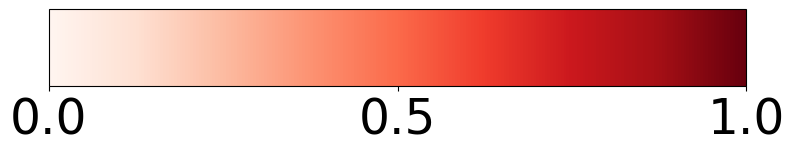

In [8]:
#plot just the  colobar from -1 to 1, (should be a slim bar)

import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib as mpl
import matplotlib.pyplot as plt

# fig, ax = plt.subplots(figsize=(12, 1))  # Adjust the figure size to make the colorbar slim
fig, ax = plt.subplots(figsize=(9, 1))  # Adjust the figure size to make the colorbar slim
cmap = cm.get_cmap('Reds')
norm = mcolors.Normalize(vmin=0, vmax=1)
cb1 = mpl.colorbar.ColorbarBase(ax, cmap=cmap,
                                norm=norm,
                                orientation= 'horizontal')#'vertical')
# cb1.set_label('Correlation Coefficient', fontsize=30)
cb1.ax.tick_params(labelsize=35)
# cb1.ax.tick_params(labelsize=20)
#only show -1,0,1
cb1.set_ticks([0, 0.5,1])
# cb1.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1])
# cb1.set_ticks([-1, -0.5,0, 0.5,1])
# cb1.set_ticks([-1,-0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1])
# cb1.set_ticks([-0.5, -0.25, 0, 0.25, 0.5])
plt.show()


In [11]:
data.shape

(81126,)

Background RRGGBBAA: ffffff00
Area 0:0:2062.8:1024 exported to 1547 x 768 pixels (72 dpi)
nan nan nan


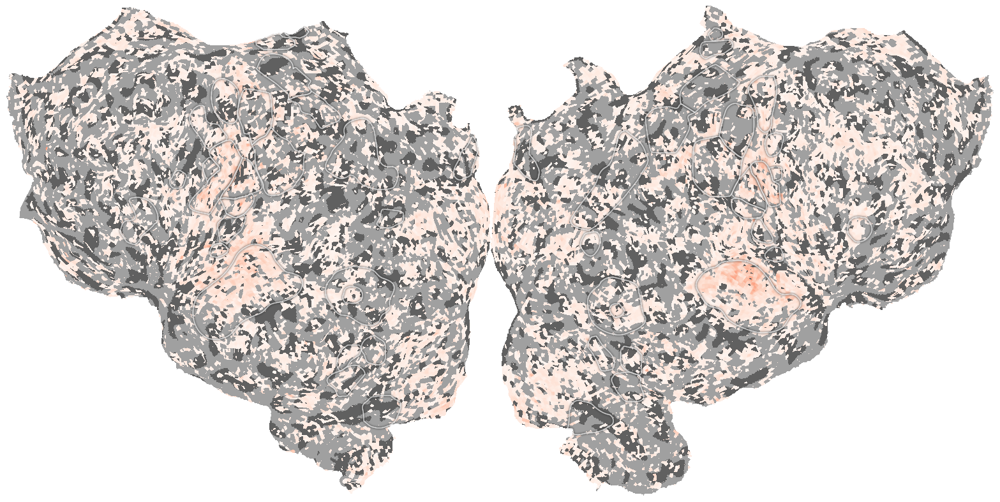

In [38]:
#some example
def filter_these_voxels(arr, filter_mask):
    """Filter out voxels based on a binary mask"""
    arr[filter_mask] = np.nan
    return arr
sub = "S3"
# data = get_measure_dict(all_results, best_models_exp_info, sub, "cc_norm")["multimodal MLP PCA"]

# data = get_measure_dict(all_results, best_models_exp_info, sub, "corrs_unnorm")["multimodal MLP PCA"]
data = get_measure_dict(all_results, best_models_exp_info, sub, "corrs_unnorm")["multimodal MLP PCA"] - get_measure_dict(all_results, best_models_exp_info, sub, "corrs_unnorm")["semantic linear all voxels"]

data = filter_these_voxels(data, data<0.0)#(np.abs(data)>0.3) | (np.abs(data)<0.05))


vol = cortex.Volume(data, subject=f"UTS0{sub[-1]}", xfmname=f"UTS0{sub[-1]}_auto", vmin=0, vmax=1, cmap='Reds')
cortex.quickshow(vol, with_colorbar=False, with_rois=True, with_labels=False, with_curvature=True, colorbar_location='center', height=768)
print(data.min(), data.max(), data.mean())

# plt.savefig(f'./FIGURES/REVISION_FIGURES/norm_plain_plot_mult_MLP_sub-{sub[-1]}.png', dpi=300, bbox_inches='tight')

# plt.show()

-0.36676572833213344 0.44545764848945135 0.021667414770963123


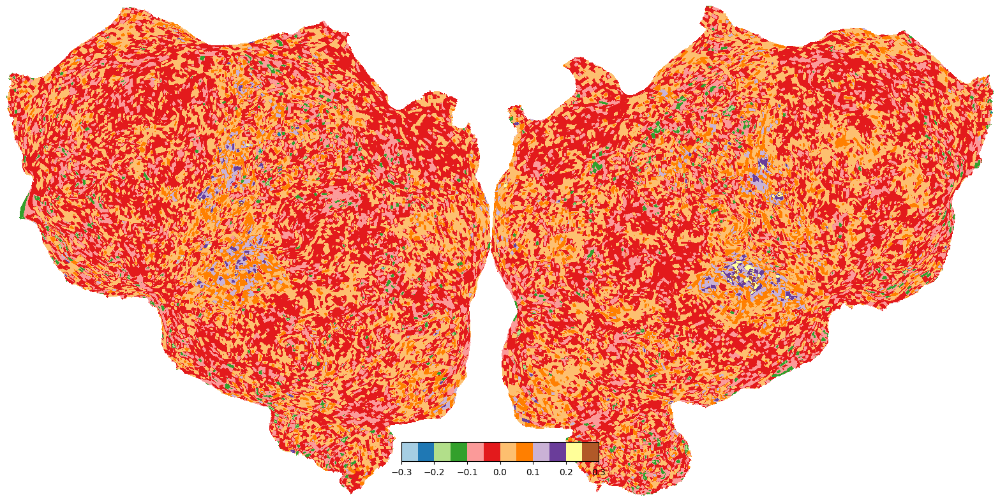

In [42]:
sub="S3"
data = get_measure_dict(all_results, best_models_exp_info, sub, "corrs_unnorm")["multimodal MLP PCA"] - get_measure_dict(all_results, best_models_exp_info, sub, "corrs_unnorm")["semantic linear all voxels"]


min = -0.3
max = 0.3
num_bins = 10

# Discretize the cc_max values into 10 bins
bins = np.linspace(min, max, num_bins +2)  # 10 bins
discretized_values = np.digitize(data, bins) - 1  # Subtract 1 to make bins 0-indexed

# Replace original values with bin indices
to_plot_discretized = bins[discretized_values]


# Some example
vol = cortex.Volume(to_plot_discretized, subject=f"UTS0{sub[-1]}", xfmname=f"UTS0{sub[-1]}_auto", vmin=min, vmax=max, cmap='Paired')
cortex.quickshow(vol, with_colorbar=True, with_rois=False, with_labels=False, with_curvature=True, colorbar_location='center', height=768)
print(data.min(), data.max(), data.mean())
                    #, vmin=0, vmax=1, cmap = "Paired") #"Paired") #'BPROG')



Text(0.5, 0, 'Correlation Coefficient Difference')

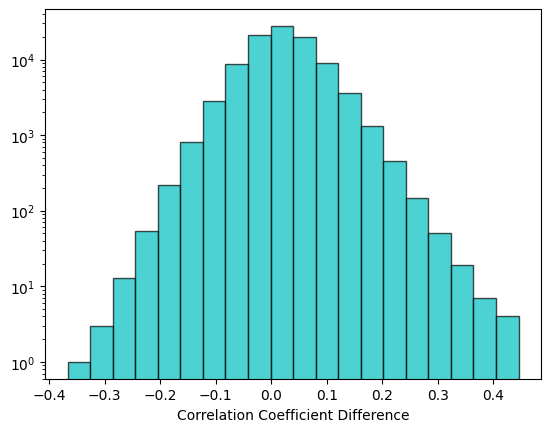

In [44]:
#get histogram of nparray data
data = get_measure_dict(all_results, best_models_exp_info, sub, "corrs_unnorm")["multimodal MLP PCA"] - get_measure_dict(all_results, best_models_exp_info, sub, "corrs_unnorm")["semantic linear all voxels"]

plt.hist(data, bins=20, color='c', edgecolor='k', alpha=0.7)
plt.yscale('log')
plt.xlabel('Correlation Coefficient Difference')


In [27]:
data.min(), data.max()

(-0.3865510390668593, 0.420962575531081)

Started server on port 30386
{'camera.azimuth': 180, 'camera.altitude': 180, 'camera.target': [0, -100, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 179.9 -> 180
{'camera.azimuth': 180, 'camera.altitude': 0, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 1, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 0, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 0.1 -> 0
{'camera.azimuth': 0, 'camera.altitude': 90, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
{'camera.azimuth': 180, 'camera.altitude': 90, 'camera.target

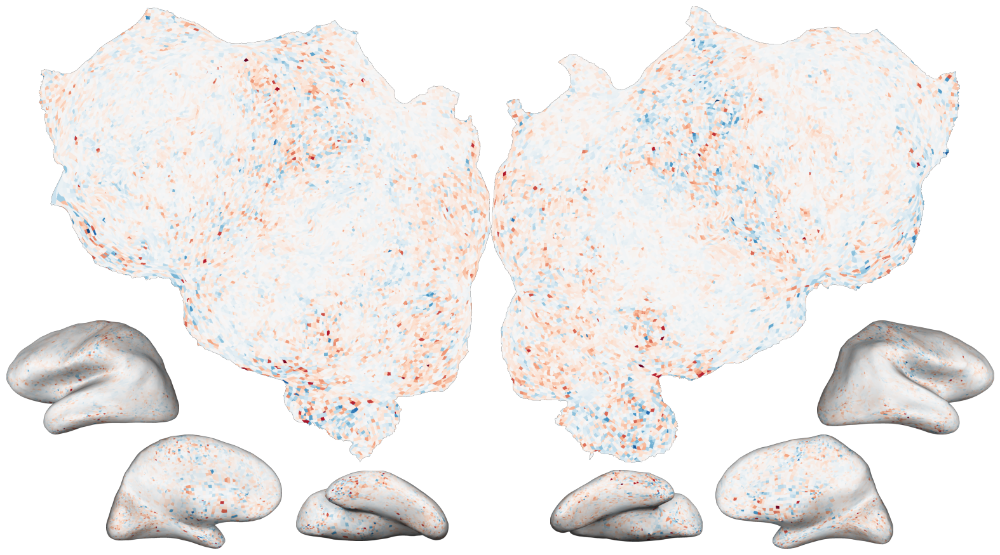

Started server on port 10437
Stopping server
{'camera.azimuth': 180, 'camera.altitude': 180, 'camera.target': [0, -100, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 179.9 -> 180
{'camera.azimuth': 180, 'camera.altitude': 0, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 1, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 0, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 0.1 -> 0
{'camera.azimuth': 0, 'camera.altitude': 90, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
{'camera.azimuth': 180, 'camera.altitude': 90

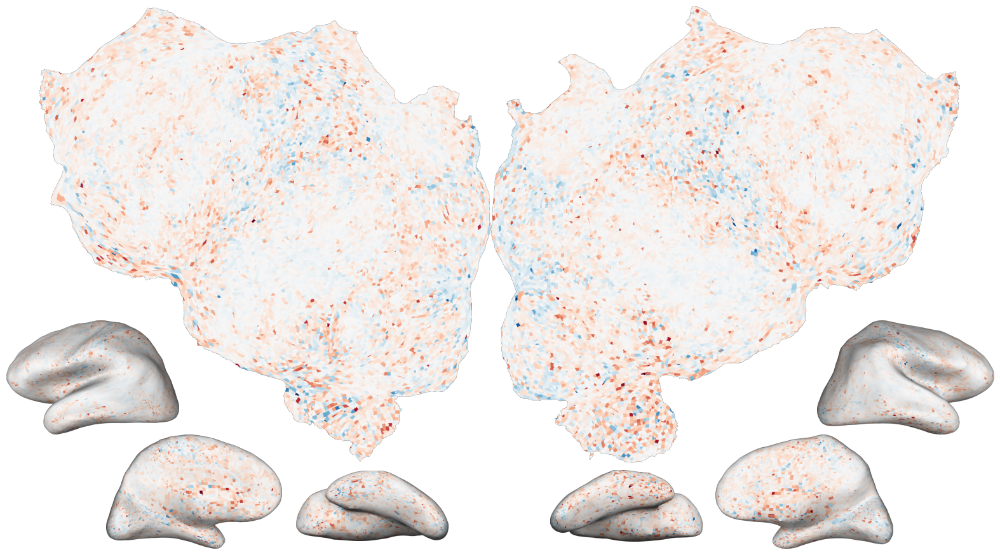

Started server on port 42167
Stopping server
{'camera.azimuth': 180, 'camera.altitude': 180, 'camera.target': [0, -100, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 179.9 -> 180
{'camera.azimuth': 180, 'camera.altitude': 0, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 1, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 0, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 0.1 -> 0
{'camera.azimuth': 0, 'camera.altitude': 90, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
{'camera.azimuth': 180, 'camera.altitude': 90

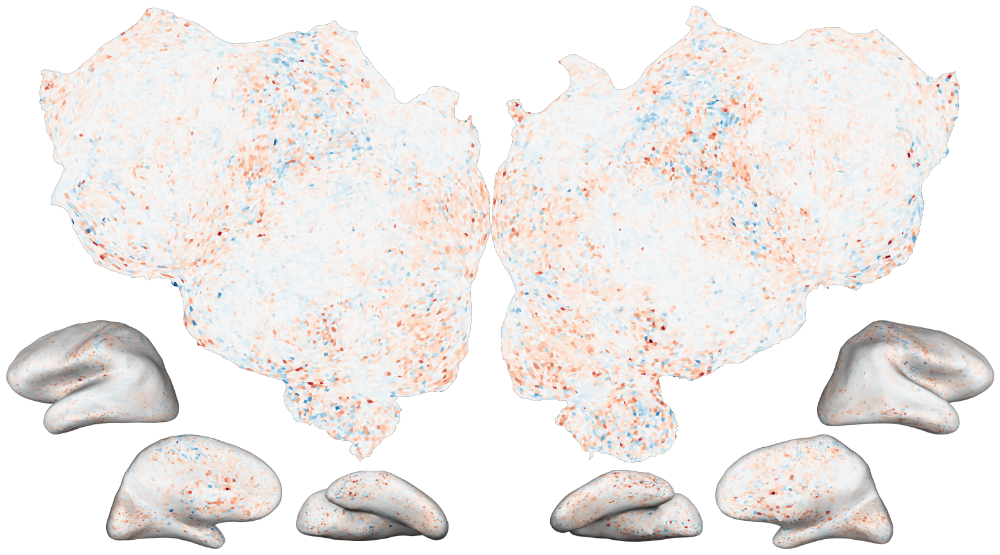

Started server on port 51601
Stopping server
{'camera.azimuth': 180, 'camera.altitude': 180, 'camera.target': [0, -100, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 179.9 -> 180
{'camera.azimuth': 180, 'camera.altitude': 0, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 1, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 0, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 0.1 -> 0
{'camera.azimuth': 0, 'camera.altitude': 90, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
{'camera.azimuth': 180, 'camera.altitude': 90

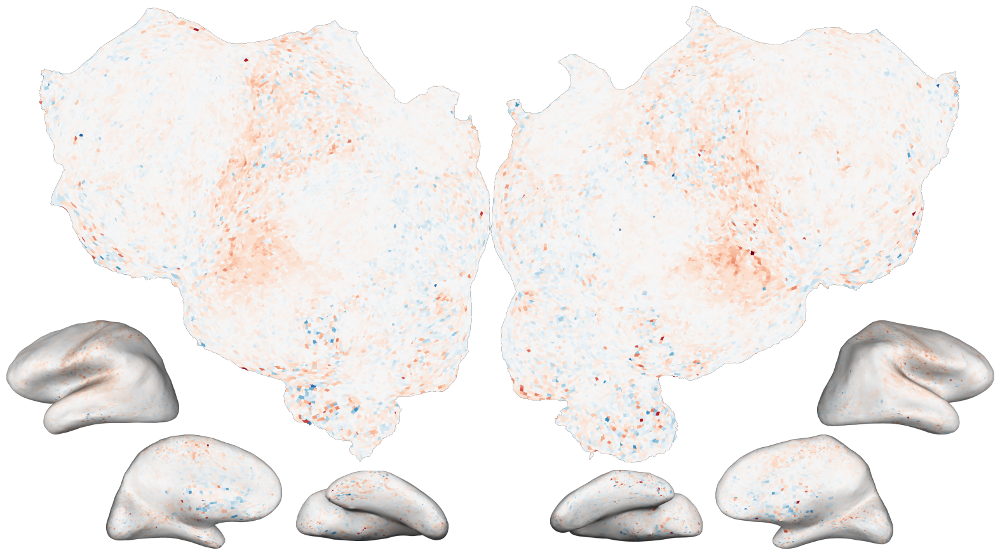

Started server on port 42325
Stopping server
{'camera.azimuth': 180, 'camera.altitude': 180, 'camera.target': [0, -100, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 179.9 -> 180
{'camera.azimuth': 180, 'camera.altitude': 0, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 1, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 0, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 0.1 -> 0
{'camera.azimuth': 0, 'camera.altitude': 90, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
{'camera.azimuth': 180, 'camera.altitude': 90

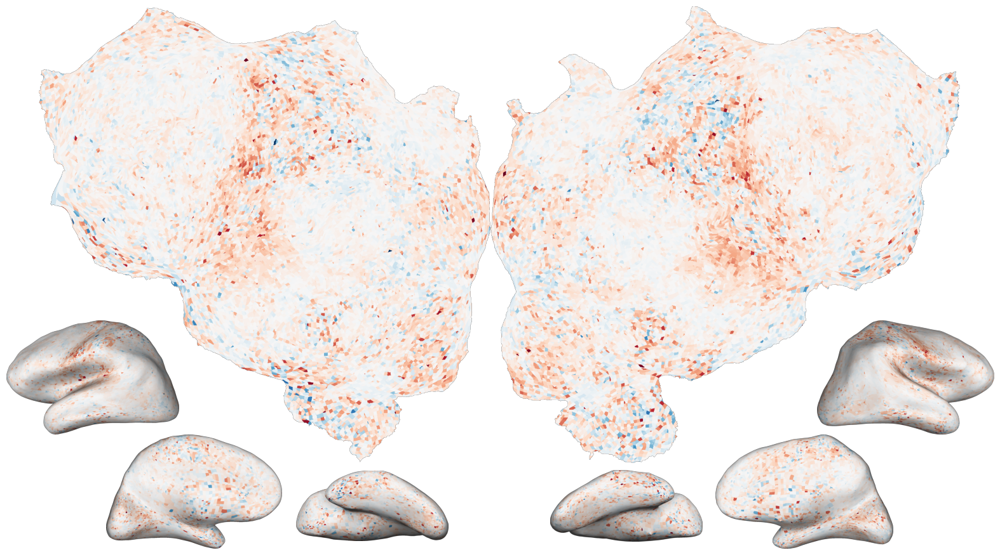

Started server on port 61314
Stopping server
{'camera.azimuth': 180, 'camera.altitude': 180, 'camera.target': [0, -100, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 179.9 -> 180
{'camera.azimuth': 180, 'camera.altitude': 0, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 1, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 0, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 0.1 -> 0
{'camera.azimuth': 0, 'camera.altitude': 90, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
{'camera.azimuth': 180, 'camera.altitude': 90

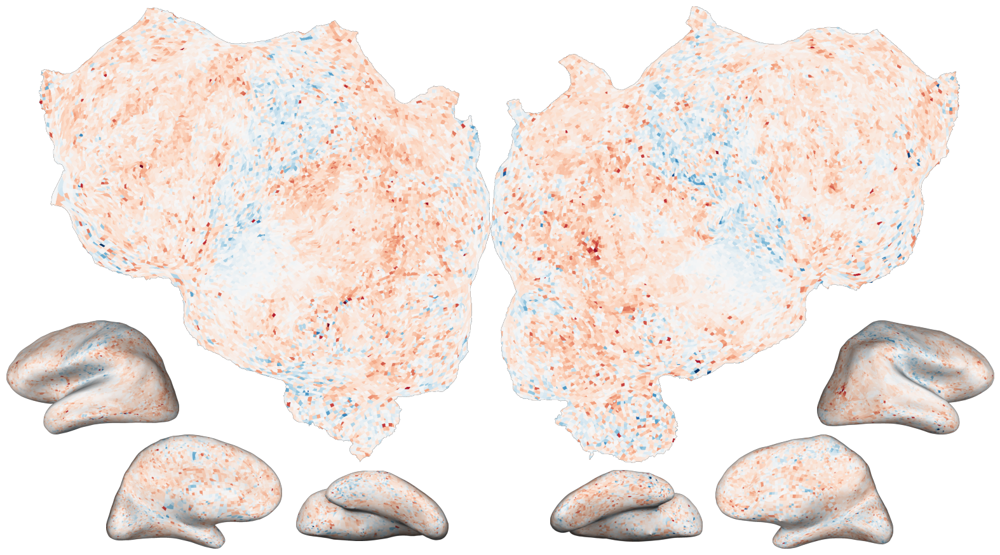

Started server on port 7591
Stopping server
{'camera.azimuth': 180, 'camera.altitude': 180, 'camera.target': [0, -100, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 179.9 -> 180
{'camera.azimuth': 180, 'camera.altitude': 0, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 1, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 0, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 0.1 -> 0
{'camera.azimuth': 0, 'camera.altitude': 90, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
{'camera.azimuth': 180, 'camera.altitude': 90,

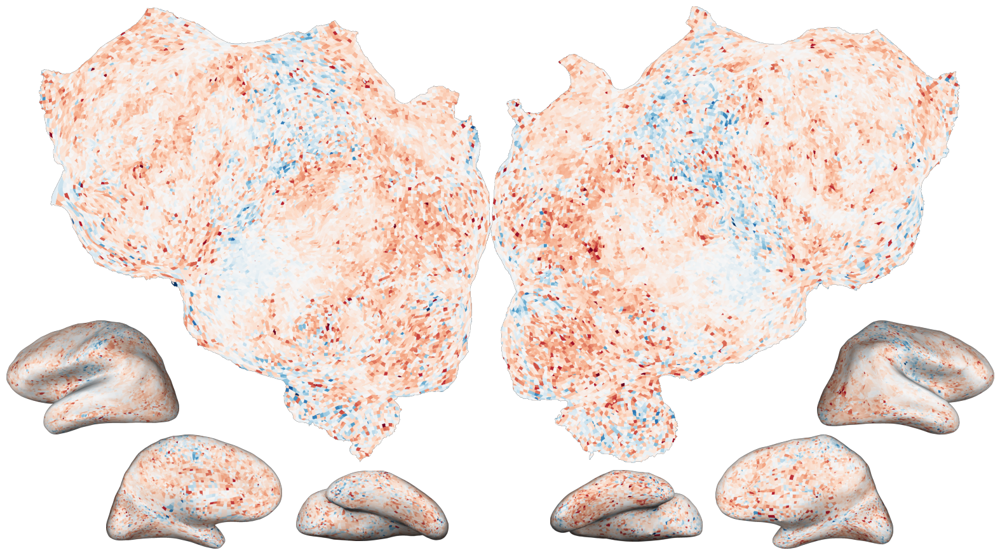

Started server on port 42749
Stopping server
{'camera.azimuth': 180, 'camera.altitude': 180, 'camera.target': [0, -100, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 179.9 -> 180
{'camera.azimuth': 180, 'camera.altitude': 0, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 1, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 0, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 0.1 -> 0
{'camera.azimuth': 0, 'camera.altitude': 90, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
{'camera.azimuth': 180, 'camera.altitude': 90

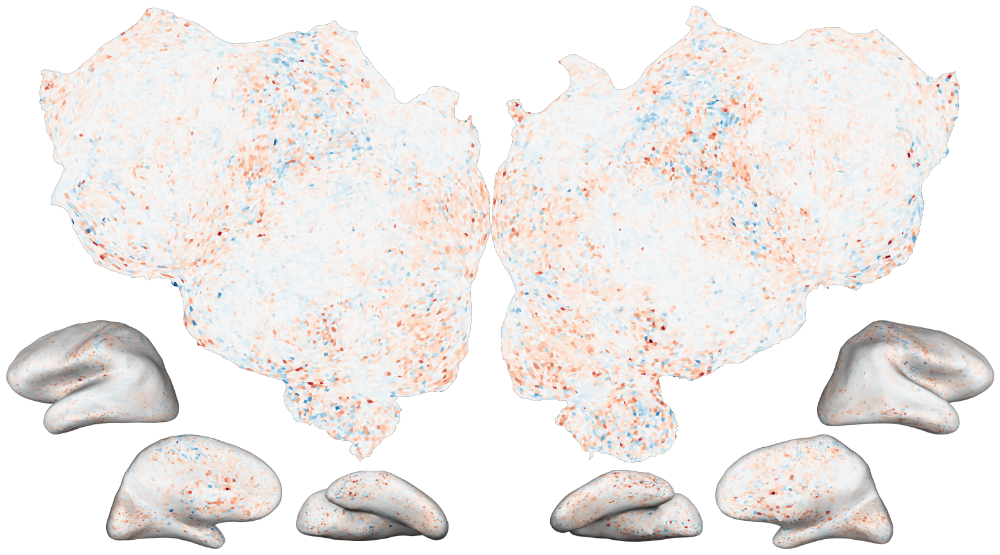

Started server on port 14060
Stopping server
{'camera.azimuth': 180, 'camera.altitude': 180, 'camera.target': [0, -100, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 179.9 -> 180
{'camera.azimuth': 180, 'camera.altitude': 0, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 1, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 0, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 0.1 -> 0
{'camera.azimuth': 0, 'camera.altitude': 90, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
{'camera.azimuth': 180, 'camera.altitude': 90

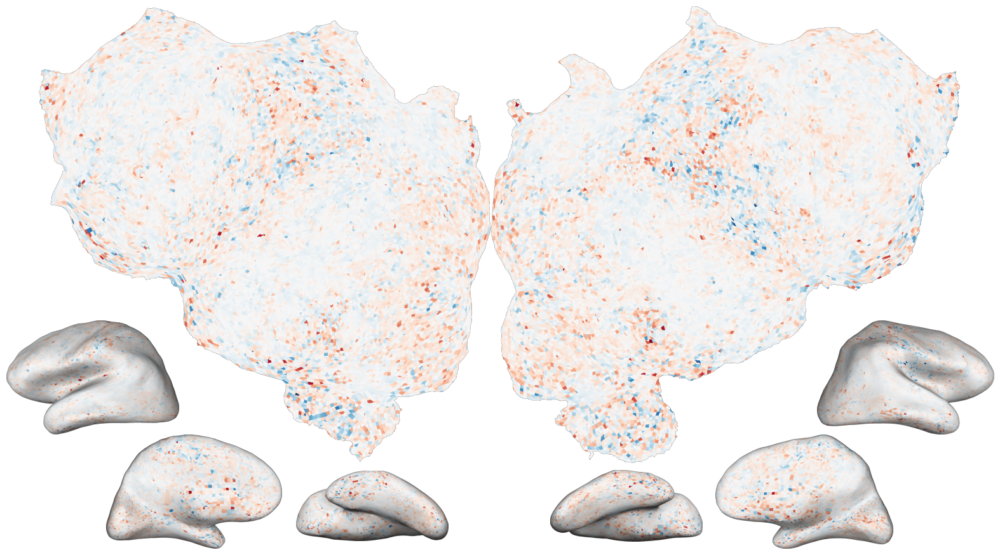

Started server on port 26990
Stopping server
{'camera.azimuth': 180, 'camera.altitude': 180, 'camera.target': [0, -100, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 179.9 -> 180
{'camera.azimuth': 180, 'camera.altitude': 0, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 1, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 0, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
waiting for camera.altitude 0.1 -> 0
{'camera.azimuth': 0, 'camera.altitude': 90, 'camera.target': [0, 0, 0], 'surface.{subject}.unfold': 0.5, 'surface.{subject}.pivot': 180, 'surface.{subject}.shift': 10, 'surface.{subject}.specularity': 0, 'surface.{subject}.sampler': 'nearest', 'surface.{subject}.layers': 1}
{'camera.azimuth': 180, 'camera.altitude': 90

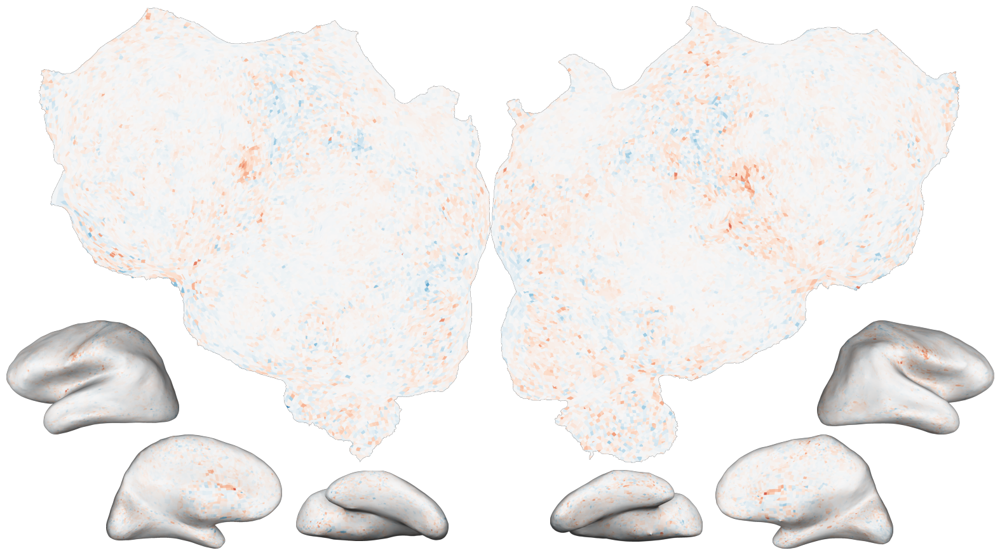

: 

In [ ]:
##define 
raw_voxelwise_value_dict = {}
measure = "cc_norm" #"corrs_unnorm" #"cc_norm" # or "corrs_unnorm"
sub = "S3"
vmin = -1
vmax = 1 

PERF_DICT = get_measure_dict(all_results, best_models_exp_info, sub, measure)    

#plain compariosn 
# raw_voxelwise_value_dict = {
#     "mult MLP"  : PERF_DICT["multimodal MLP PCA"],
#     "mult linear" : PERF_DICT["multimodal linear all voxels"],
#     "sem MLP" : PERF_DICT["semantic MLP PCA"],
#     "sem linear" : PERF_DICT["semantic linear all voxels"],
#     "audio MLP" : PERF_DICT["audio MLP PCA"],   
#     "audio linear" : PERF_DICT["audio linear all voxels"],
# }

#delta corr_norm
raw_voxelwise_value_dict = {
    "perf_diff_from_nonlinearity_semantic" : PERF_DICT["semantic MLP PCA"] - PERF_DICT["semantic linear all voxels"],
    "perf_diff_from_nonlinearity_audio" : PERF_DICT["audio MLP PCA"] - PERF_DICT["audio linear all voxels"],
    "perf_diff_from_nonlinearity_multimodal" : PERF_DICT["multimodal MLP PCA"] - PERF_DICT["multimodal linear all voxels"],
    "perf_diff_mult linear - sem linear" : PERF_DICT["multimodal linear all voxels"] - PERF_DICT["semantic linear all voxels"],
    "perf_diff_mult MLP - sem linear " : PERF_DICT["multimodal MLP PCA"] - PERF_DICT["semantic linear all voxels"],
    "perf_diff_mult linear  - audio linear" : PERF_DICT["multimodal linear all voxels"] - PERF_DICT["audio linear all voxels"],
    "perf_diff_mult MLP - audio linear" : PERF_DICT["multimodal MLP PCA"] - PERF_DICT["audio linear all voxels"],
    "perf_diff_mult MLP - mult linear" : PERF_DICT["multimodal MLP PCA"] - PERF_DICT["multimodal linear all voxels"],
    "perf_diff_mult SepMLP - mult linear" : PERF_DICT["multimodal SepMLP PCA"] - PERF_DICT["multimodal linear all voxels"],
    "perf_diff_mult MLP - mult SepMLP" : PERF_DICT["multimodal MLP PCA"] - PERF_DICT["multimodal SepMLP PCA"],
}

################

# value = get_measure_dict(all_results, best_models_exp_info, sub, "cc_norm")["multimodal MLP PCA"]

# params = cortex.export.params_inflatedless_lateral_medial_ventral
cmap = "Reds" if vmin == 0 else None
if cmap is not None : 
    volume_dict = {key : cortex.Volume(data = value, subject = f'UTS0{sub[-1]}', xfmname = f"UTS0{sub[-1]}_auto", vmin = vmin, vmax = vmax, cmap=cmap) for key, value in raw_voxelwise_value_dict.items()}
else : 
    volume_dict = {key : cortex.Volume(data = value, subject = f'UTS0{sub[-1]}', xfmname = f"UTS0{sub[-1]}_auto", vmin = vmin, vmax = vmax) for key, value in raw_voxelwise_value_dict.items()}

params = cortex.export.params_flatmap_inflated_lateral_medial_ventral 

# viewer_params = {"overlays_visible" : ["rois", 'sulci'], "labels_visible" : ['rois']}
# viewer_params = {"overlays_visible" : ['sulci'], "labels_visible" : ['rois']}
viewer_params = {"overlays_visible" : [], "labels_visible" : []}


for key, value in volume_dict.items():
    cortex.export.plot_panels(value, **params, viewer_params = viewer_params)
    # plt.title(key)
    #save the figure
    plt.savefig(f'./FIGURES/REVISION_FIGURES/{sub}_{key}_{measure}_flatmap.png', dpi=700, bbox_inches='tight')
    plt.show()


# params = cortex.export.params_occipital_triple_view
# cortex.export.plot_panels(volume, **params)
# plt.show()
# #port=
# #ssh -L $port:localhost:$port dyhan316@114.110.129.216
# #http://localhost:{XX}/mixer.html